In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [2]:
# ============================================================================
# CELL 1: Installation et imports (INDÉPENDANT)
# ============================================================================

!pip install joblib seaborn scikit-learn -q

import os
import warnings
import logging
import glob
import gc
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

os.environ['HDF5_PLUGIN_PATH'] = '/tmp/hdf5_plugins'
os.makedirs('/tmp/hdf5_plugins', exist_ok=True)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'

warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

print('='*60)
print('WASHING MACHINE NILM - Version améliorée (50 epochs)')
print('='*60)
print(f'TensorFlow: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')

E0000 00:00:1777216835.755477      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777216835.871844      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777216836.989898      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777216836.989942      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777216836.989945      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777216836.989947      23 computation_placer.cc:177] computation placer already registered. Please check linka

WASHING MACHINE NILM - Version améliorée (50 epochs)
TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
# ============================================================================
# CELL 2: Configuration WASHING MACHINE (INDÉPENDANT)
# ============================================================================

class Config:
    """Configuration spécifique pour la WASHING MACHINE"""
    
    # Paramètres du modèle
    WINDOW_SIZE = 599          # 599 points = 59.9 minutes
    BATCH_SIZE = 256
    EPOCHS = 20
    LR = 1e-3
    VAL_SPLIT = 0.15
    SEED = 42
    FREQ = '6s'
    
    # Limites mémoire
    MAX_TRAIN_SAMPLES = 500_000
    MAX_TEST_SAMPLES = 100_000
    
    H5_PATH = None
    
    # PARAMÈTRES WASHING MACHINE
    # IMPORTANT: La washing machine est sur meter5 dans house_1
    # et meter12 dans house_2, meter6 dans house_4, meter24 dans house_5
    WASHING_MACHINE = {
        'name': 'WashingMachine',
        'meters': {  # Différents compteurs selon la maison
            1: 5,    # house_1: washer dryer sur meter5
            2: 12,   # house_2: washing machine sur meter12
            4: 6,    # house_4: washing machine sur meter6
            5: 24,   # house_5: washer dryer sur meter24
        },
        'default_meter': 5,
        'threshold': 20,      # Seuil plus élevé pour washing machine
        'max_power': 2500,
        'mean_on': 500,
        'std_on': 800,
        'color': '#FF6B6B',
        'window_minutes': 120  # Cycles plus longs
    }
    
    # Configuration des maisons
    UKDALE_HOUSES = {
        'house_1': {
            'name': 'UKDALE-1',
            'house_id': 1,
            'train': ('2013-04-01', '2014-03-31'),
            'test': ('2014-04-01', '2014-05-01'),
        },
        'house_2': {
            'name': 'UKDALE-2',
            'house_id': 2,
            'test': ('2013-07-28', '2013-08-11'),
        },
        'house_4': {
            'name': 'UKDALE-4',
            'house_id': 4,
            'test': ('2013-05-01', '2013-06-01'),
        },
        'house_5': {
            'name': 'UKDALE-5',
            'house_id': 5,
            'test': ('2014-06-20', '2014-06-30'),
        }
    }
    
    @classmethod
    def get_meter(cls, house_id=1):
        """Retourne le meter pour une maison donnée"""
        return f"meter{cls.WASHING_MACHINE['meters'].get(house_id, cls.WASHING_MACHINE['default_meter'])}"
    
    @classmethod
    def get_threshold(cls):
        return cls.WASHING_MACHINE['threshold']
    
    @classmethod
    def get_window_minutes(cls):
        return cls.WASHING_MACHINE['window_minutes']


# Trouver le fichier H5
h5_files = glob.glob('/kaggle/input/**/*.h5', recursive=True)
if h5_files:
    Config.H5_PATH = h5_files[0]
    print(f"✅ Fichier trouvé: {Config.H5_PATH}")
else:
    print("❌ Aucun fichier .h5 trouvé!")

tf.random.set_seed(Config.SEED)
np.random.seed(Config.SEED)

print("="*60)
print("CONFIGURATION WASHING MACHINE")
print("="*60)
print(f"Appareil: {Config.WASHING_MACHINE['name']}")
print(f"Compteurs par maison: {Config.WASHING_MACHINE['meters']}")
print(f"Seuil ON/OFF: {Config.WASHING_MACHINE['threshold']} W")
print(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print(f"Batch size: {Config.BATCH_SIZE}")
print(f"Epochs: {Config.EPOCHS}")

✅ Fichier trouvé: /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5
CONFIGURATION WASHING MACHINE
Appareil: WashingMachine
Compteurs par maison: {1: 5, 2: 12, 4: 6, 5: 24}
Seuil ON/OFF: 20 W
Window size: 599 pts = 60 min
Batch size: 256
Epochs: 20


In [4]:
# ============================================================================
# CELL 3: Chargeur de données UK-DALE corrigé (INDÉPENDANT)
# ============================================================================

class UKDALEDataLoader:
    """Chargeur de données UK-DALE spécialisé WASHING MACHINE (Version corrigée)"""
    
    def __init__(self, h5_path):
        self.h5_path = h5_path
        self._cache = {}
    
    def read_meter(self, building, meter, max_points=None):
        cache_key = f"b{building}_{meter}"
        if cache_key in self._cache:
            return self._cache[cache_key]
        
        try:
            key = f'building{building}/elec/{meter}'
            s = pd.read_hdf(self.h5_path, key=key)
            if isinstance(s, pd.DataFrame):
                s = s.iloc[:, 0]
            s = s.astype(np.float32)
            s = s[~s.index.duplicated(keep='first')]
            s = s.sort_index()
            if max_points and len(s) > max_points:
                s = s.iloc[:max_points]
            self._cache[cache_key] = s
            return s
        except Exception as e:
            print(f"   ⚠️ Impossible de lire {meter} pour building{building}: {e}")
            return None
    
    def _to_tz_aware(self, date_str, tz='Europe/London'):
        if date_str is None:
            return None
        dt = pd.Timestamp(date_str)
        if dt.tz is None:
            dt = dt.tz_localize(tz)
        return dt
    
    def get_available_meters(self, building):
        """Retourne la liste des compteurs disponibles pour un building"""
        try:
            key = f'building{building}/elec'
            with h5py.File(self.h5_path, 'r') as f:
                if key in f:
                    return list(f[key].keys())
        except:
            pass
        return []
    
    def load_house_data(self, house_key, mode='train', max_samples=None):
        if house_key not in Config.UKDALE_HOUSES:
            raise ValueError(f"Maison {house_key} non trouvée")
        
        house_config = Config.UKDALE_HOUSES[house_key]
        house_id = house_config['house_id']
        
        if mode == 'train':
            if 'train' not in house_config:
                print(f"⚠️ Pas de période d'entraînement pour {house_key}")
                return None
            start_date = self._to_tz_aware(house_config['train'][0])
            end_date = self._to_tz_aware(house_config['train'][1])
        else:
            if 'test' not in house_config:
                print(f"⚠️ Pas de période de test pour {house_key}")
                return None
            start_date = self._to_tz_aware(house_config['test'][0])
            end_date = self._to_tz_aware(house_config['test'][1])
        
        print(f"\n{'='*50}")
        print(f"{mode.upper()}: {house_config['name']}")
        print(f"Période: {start_date.date()} → {end_date.date()}")
        print(f"{'='*50}")
        
        # Vérifier les compteurs disponibles
        available_meters = self.get_available_meters(house_id)
        print(f"Compteurs disponibles dans building{house_id}: {len(available_meters)}")
        
        # Trouver le bon compteur pour la machine à laver
        wm_meter_num = Config.WASHING_MACHINE['meters'].get(house_id, Config.WASHING_MACHINE['default_meter'])
        wm_meter = f"meter{wm_meter_num}"
        
        # Si le compteur spécifique n'existe pas, chercher d'autres compteurs possibles
        if wm_meter not in available_meters:
            # Chercher des alternatives
            alternatives = ['meter5', 'meter12', 'meter6', 'meter24']
            for alt in alternatives:
                if alt in available_meters:
                    wm_meter = alt
                    print(f"   📌 Utilisation alternative: {wm_meter}")
                    break
            else:
                print(f"❌ Aucun compteur de machine à laver trouvé pour building{house_id}")
                return None
        
        all_meters = {}
        monitored_meters = []
        
        # Washing Machine
        s = self.read_meter(house_id, wm_meter)
        if s is not None and len(s) > 0:
            all_meters[wm_meter] = s
            monitored_meters.append(wm_meter)
            print(f"✅ {wm_meter}: {len(s):,} points")
        else:
            print(f"❌ {wm_meter} non trouvé ou vide!")
            # Afficher les compteurs disponibles pour debug
            print(f"   Compteurs disponibles: {available_meters[:20]}...")
            return None
        
        # Autres compteurs pour la somme (limiter pour éviter mémoire)
        max_meters = 30  # Limite pour éviter trop de mémoire
        meters_loaded = 0
        for meter in available_meters:
            if meter != wm_meter and meter not in all_meters and meters_loaded < max_meters:
                s = self.read_meter(house_id, meter)
                if s is not None and len(s) > 0:
                    all_meters[meter] = s
                    monitored_meters.append(meter)
                    meters_loaded += 1
        
        print(f"✅ {len(all_meters)} compteurs chargés")
        
        # Grille temporelle
        start_dates = [s.index.min() for s in all_meters.values()]
        end_dates = [s.index.max() for s in all_meters.values()]
        common_start = max(start_dates)
        common_end = min(end_dates)
        
        grid_start = max(common_start, start_date)
        grid_end = min(common_end, end_date)
        
        if grid_start >= grid_end:
            print(f"❌ Période invalide: {grid_start} → {grid_end}")
            return None
        
        grid = pd.date_range(grid_start, grid_end, freq=Config.FREQ, tz='Europe/London')
        
        print(f"Grille: {len(grid):,} points")
        
        # DataFrame
        df_dict = {}
        for meter, series in all_meters.items():
            df_dict[meter] = series.reindex(grid, method='nearest', tolerance=Config.FREQ).fillna(0)
        
        df = pd.DataFrame(df_dict)
        
        if max_samples and len(df) > max_samples:
            df = df.iloc[:max_samples]
        
        # Statistiques washing machine
        wm_power = df[wm_meter].values
        threshold = Config.get_threshold()
        
        if len(wm_power) == 0:
            print(f"❌ Aucune donnée pour {wm_meter} après réindexation!")
            return None
        
        print(f"\n📊 WASHING MACHINE ({wm_meter}) - {mode}:")
        print(f"   Max: {wm_power.max():.0f} W")
        print(f"   Moy: {wm_power.mean():.1f} W")
        print(f"   ON (> {threshold}W): {(wm_power > threshold).mean()*100:.2f}%")
        
        return {
            'name': house_config['name'],
            'house_id': house_id,
            'house_key': house_key,
            'df': df,
            'wm_meter': wm_meter,
            'monitored_meters': monitored_meters,
        }
    
    def clear_cache(self):
        self._cache.clear()
        gc.collect()


if Config.H5_PATH and os.path.exists(Config.H5_PATH):
    loader = UKDALEDataLoader(Config.H5_PATH)
    print("✅ Chargeur UK-DALE initialisé (version corrigée)")
else:
    loader = None

✅ Chargeur UK-DALE initialisé (version corrigée)


In [5]:
# ============================================================================
# CELL 4: Chargement des données WASHING MACHINE (INDÉPENDANT)
# ============================================================================

print("\n" + "="*60)
print("CHARGEMENT DES DONNÉES WASHING MACHINE")
print("="*60)

if loader is None:
    print("❌ Chargeur non disponible")
    DATA_TRAIN = None
    DATA_TEST = None
else:
    print("\n📚 Tentative chargement données d'entraînement (house_1):")
    DATA_TRAIN = loader.load_house_data('house_1', mode='train', max_samples=Config.MAX_TRAIN_SAMPLES)
    
    if DATA_TRAIN is None:
        print("\n⚠️ Impossible de charger house_1 pour l'entraînement")
        print("   Essayons une autre maison pour l'entraînement...")
        
        # Alternative: utiliser house_2 ou house_5 pour l'entraînement
        for alt_house in ['house_2', 'house_5']:
            print(f"\n📚 Tentative avec {alt_house}:")
            DATA_TRAIN = loader.load_house_data(alt_house, mode='train', max_samples=Config.MAX_TRAIN_SAMPLES)
            if DATA_TRAIN is not None:
                print(f"✅ Utilisation de {alt_house} pour l'entraînement")
                break
    
    print("\n🔬 Chargement données de test (house_2):")
    DATA_TEST = loader.load_house_data('house_2', mode='test', max_samples=Config.MAX_TEST_SAMPLES)
    
    if DATA_TEST is None:
        print("\n🔬 Tentative avec house_4 pour le test:")
        DATA_TEST = loader.load_house_data('house_4', mode='test', max_samples=Config.MAX_TEST_SAMPLES)
    
    if DATA_TRAIN is None:
        print("\n❌ Aucune donnée d'entraînement disponible!")
    else:
        print(f"\n✅ Données d'entraînement prêtes:")
        print(f"   Train: {DATA_TRAIN['df'].shape}")
        print(f"   Maison d'entraînement: {DATA_TRAIN['name']}")
        print(f"   Compteur utilisé: {DATA_TRAIN['wm_meter']}")
    
    if DATA_TEST:
        print(f"\n✅ Données de test prêtes:")
        print(f"   Test: {DATA_TEST['df'].shape}")
        print(f"   Maison de test: {DATA_TEST['name']}")
        print(f"   Compteur utilisé: {DATA_TEST['wm_meter']}")

# Stocker les données pour les cellules suivantes
if DATA_TRAIN is not None:
    print("\n💾 Variables disponibles: DATA_TRAIN, DATA_TEST")


CHARGEMENT DES DONNÉES WASHING MACHINE

📚 Tentative chargement données d'entraînement (house_1):

TRAIN: UKDALE-1
Période: 2013-04-01 → 2014-03-31
Compteurs disponibles dans building1: 54
✅ meter5: 19,555,935 points
✅ 31 compteurs chargés
Grille: 502,372 points

📊 WASHING MACHINE (meter5) - train:
   Max: 3959 W
   Moy: 31.8 W
   ON (> 20W): 4.61%

🔬 Chargement données de test (house_2):

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
Compteurs disponibles dans building2: 21
✅ meter12: 1,686,220 points
   ⚠️ Impossible de lire cache pour building2: cannot create a storer if the object is not existing nor a value are passed
✅ 20 compteurs chargés
Grille: 201,601 points

📊 WASHING MACHINE (meter12) - test:
   Max: 2379 W
   Moy: 13.2 W
   ON (> 20W): 1.66%

✅ Données d'entraînement prêtes:
   Train: (500000, 31)
   Maison d'entraînement: UKDALE-1
   Compteur utilisé: meter5

✅ Données de test prêtes:
   Test: (100000, 20)
   Maison de test: UKDALE-2
   Compteur utilisé: meter12

💾 Vari

In [6]:
# ============================================================================
# CELL 5: Fonctions de fenêtrage et métriques NILM (INDÉPENDANT)
# ============================================================================

def create_windows(data, window_size=Config.WINDOW_SIZE, target_type='point'):
    """Crée des fenêtres glissantes"""
    values = data.values if isinstance(data, pd.Series) else np.array(data)
    values = values.astype(np.float32)
    
    pad = window_size // 2
    values_padded = np.pad(values, (pad, pad), 'constant', constant_values=0)
    
    X = np.array([
        values_padded[i:i + window_size]
        for i in range(len(values))
    ], dtype=np.float32)
    X = X[..., np.newaxis]
    
    if target_type == 'point':
        y = values
    else:
        y = np.array([
            values_padded[i:i + window_size]
            for i in range(len(values))
        ], dtype=np.float32)
    
    return X, y


class NILMMetrics:
    """Métriques NILM"""
    
    @staticmethod
    def estimation_accuracy(y_true, y_pred):
        numerator = np.sum(np.abs(y_true - y_pred))
        denominator = 2 * np.sum(y_true)
        if denominator == 0:
            return 1.0 if numerator == 0 else 0.0
        return float(np.clip(1 - numerator / denominator, 0, 1))
    
    @staticmethod
    def f_measure(y_true, y_pred, threshold):
        y_true_bin = (y_true > threshold).astype(int)
        y_pred_bin = (y_pred > threshold).astype(int)
        
        cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])
        if cm.shape != (2, 2):
            return 0.0
        
        tn, fp, fn, tp = cm.ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        
        if precision + recall == 0:
            return 0.0
        return 2 * precision * recall / (precision + recall)
    
    @staticmethod
    def compute_all(y_true, y_pred, threshold):
        ea = NILMMetrics.estimation_accuracy(y_true, y_pred)
        fm = NILMMetrics.f_measure(y_true, y_pred, threshold)
        rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
        mae = np.mean(np.abs(y_true - y_pred))
        corr = np.corrcoef(y_true, y_pred)[0, 1] if y_true.std() > 0 else 0
        
        return {'ea': ea, 'fm': fm, 'rmse': rmse, 'mae': mae, 'corr': corr}


print(f"✅ create_windows() — window_size={Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print("✅ NILMMetrics défini")

✅ create_windows() — window_size=599 pts = 60 min
✅ NILMMetrics défini


In [7]:
# ============================================================================
# CELL 6: Architectures CNN (INDÉPENDANT)
# ============================================================================

def create_seq2point(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """Modèle Seq2Point CNN"""
    inputs = keras.Input(shape=(window_size, 1), name='mains_input')
    
    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='linear', name='power_output')(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name='seq2point')


def create_seq2seq(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """Modèle Seq2Seq CNN"""
    inputs = keras.Input(shape=(window_size, 1), name='mains_input')
    
    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(window_size, activation='linear', name='seq_output')(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name='seq2seq')


s2p = create_seq2point()
s2s = create_seq2seq()

print(f"\n{'='*50}")
print("Architectures CNN - WASHING MACHINE")
print(f"{'='*50}")
print(f"Seq2Point: {s2p.count_params():,} paramètres")
print(f"Seq2Seq:   {s2s.count_params():,} paramètres")

I0000 00:00:1777216995.543608      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777216995.550011      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Architectures CNN - WASHING MACHINE
Seq2Point: 30,709,049 paramètres
Seq2Seq:   31,321,999 paramètres


In [8]:
# ============================================================================
# CELL 7: Fonctions d'entraînement et prédiction (INDÉPENDANT)
# ============================================================================

def train_washingmachine(train_data, model_type='seq2point', epochs=Config.EPOCHS):
    """Entraîne le modèle washing machine"""
    
    if train_data is None:
        print("❌ Données d'entraînement non disponibles")
        return None
    
    df = train_data['df']
    wm_meter = train_data['wm_meter']
    
    if wm_meter not in df.columns:
        print(f"❌ {wm_meter} non trouvé!")
        return None
    
    train_mains = df[train_data['monitored_meters']].sum(axis=1).values
    train_wm = df[wm_meter].values
    threshold = Config.get_threshold()
    
    print("\n" + "="*60)
    print(f"🚀 ENTRAÎNEMENT WASHING MACHINE - {model_type.upper()} ({epochs} epochs)")
    print("="*60)
    print(f"Compteur: {wm_meter}")
    print(f"Window: {Config.WINDOW_SIZE} pts ({Config.WINDOW_SIZE*6/60:.0f} min)")
    print(f"Epochs: {epochs}")
    print(f"\n📊 Statistiques entraînement:")
    print(f"   Mains - moy={train_mains.mean():.1f}W, max={train_mains.max():.0f}W")
    print(f"   Washing Machine - moy={train_wm.mean():.1f}W, max={train_wm.max():.0f}W")
    print(f"   ON (> {threshold}W): {(train_wm > threshold).mean()*100:.2f}%")
    
    # Normalisation
    mains_scaler = StandardScaler()
    wm_scaler = StandardScaler()
    
    mains_norm = mains_scaler.fit_transform(train_mains.reshape(-1, 1)).flatten()
    wm_norm = wm_scaler.fit_transform(train_wm.reshape(-1, 1)).flatten()
    
    # Fenêtres
    X, _ = create_windows(mains_norm, target_type='point')
    n = min(len(X), len(wm_norm))
    X = X[:n]
    
    if model_type == 'seq2point':
        y = wm_norm[:n]
    else:
        pad = Config.WINDOW_SIZE // 2
        padded = np.pad(wm_norm, (pad, pad), 'constant')
        y = np.array([padded[i:i + Config.WINDOW_SIZE] for i in range(n)], dtype=np.float32)
    
    # Split
    val_size = int(Config.VAL_SPLIT * n)
    X_train, X_val = X[:-val_size], X[-val_size:]
    y_train, y_val = y[:-val_size], y[-val_size:]
    
    print(f"\n  Train: {len(X_train):,} | Val: {len(X_val):,}")
    
    # Modèle
    model = create_seq2point() if model_type == 'seq2point' else create_seq2seq()
    model.compile(optimizer=keras.optimizers.Adam(Config.LR), loss='mse', metrics=['mae'])
    
    # Callbacks
    checkpoint_path = f'washingmachine_{model_type}.keras'
    callbacks_list = [
        callbacks.ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
    ]
    
    # Entraînement
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=Config.BATCH_SIZE,
        callbacks=callbacks_list,
        verbose=1
    )
    
    # Charger le meilleur modèle
    if os.path.exists(checkpoint_path):
        model = keras.models.load_model(checkpoint_path)
        print(f"\n✅ Meilleur modèle chargé: {checkpoint_path}")
    
    return {
        'model': model,
        'mains_scaler': mains_scaler,
        'wm_scaler': wm_scaler,
        'history': history.history,
        'best_epoch': np.argmin(history.history['val_loss']) + 1
    }


def predict_washingmachine(mains_series, model_info, model_type='seq2point'):
    """Prédiction pour la washing machine"""
    
    mains_norm = model_info['mains_scaler'].transform(mains_series.values.reshape(-1, 1)).flatten()
    X, _ = create_windows(mains_norm, target_type='point')
    
    predictions = []
    batch_size = 512
    
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size]
        pred = model_info['model'].predict(batch, verbose=0)
        
        if model_type == 'seq2point':
            predictions.append(pred.flatten())
        else:
            mid = Config.WINDOW_SIZE // 2
            predictions.append(pred[:, mid])
    
    pred_flat = np.concatenate(predictions)
    
    n = len(mains_series)
    if len(pred_flat) > n:
        pred_flat = pred_flat[:n]
    elif len(pred_flat) < n:
        pred_flat = np.pad(pred_flat, (0, n - len(pred_flat)), 'edge')
    
    return model_info['wm_scaler'].inverse_transform(pred_flat.reshape(-1, 1)).flatten()


print("✅ train_washingmachine() défini")
print("✅ predict_washingmachine() défini")

✅ train_washingmachine() défini
✅ predict_washingmachine() défini


In [9]:
# ============================================================================
# CELL 8: Entraînement Seq2Point et Seq2Seq (INDÉPENDANT) - Version robuste
# ============================================================================

print("\n" + "="*60)
print("ENTRAÎNEMENT WASHING MACHINE (50 EPOCHS)")
print("="*60)

if DATA_TRAIN is None:
    print("❌ Données d'entraînement non disponibles")
    print("\n💡 Suggestion: Vérifiez que le fichier UK-DALE contient bien les compteurs")
    print("   Exécutez la cellule de vérification pour voir les compteurs disponibles.")
    washingmachine_models = None
else:
    washingmachine_models = {}
    
    # Vérifier que les données contiennent des cycles actifs
    wm_power = DATA_TRAIN['df'][DATA_TRAIN['wm_meter']].values
    threshold = Config.get_threshold()
    active_percent = (wm_power > threshold).mean() * 100
    
    if active_percent < 1:
        print(f"\n⚠️ Attention: Seulement {active_percent:.2f}% de temps actif")
        print("   Le modèle pourrait ne pas bien apprendre")
    
    # Entraînement Seq2Point
    if 'seq2point' not in washingmachine_models:
        print("\n" + "▶"*30)
        print("ENTRAÎNEMENT SEQ2POINT")
        print("▶"*30)
        try:
            washingmachine_models['seq2point'] = train_washingmachine(DATA_TRAIN, 'seq2point', epochs=Config.EPOCHS)
        except Exception as e:
            print(f"❌ Erreur lors de l'entraînement Seq2Point: {e}")
            washingmachine_models['seq2point'] = None
    
    # Entraînement Seq2Seq
    print("\n" + "▶"*30)
    print("ENTRAÎNEMENT SEQ2SEQ")
    print("▶"*30)
    try:
        washingmachine_models['seq2seq'] = train_washingmachine(DATA_TRAIN, 'seq2seq', epochs=Config.EPOCHS)
    except Exception as e:
        print(f"❌ Erreur lors de l'entraînement Seq2Seq: {e}")
        washingmachine_models['seq2seq'] = None
    
    print("\n" + "="*60)
    print("✅ ENTRAÎNEMENT TERMINÉ")
    print("="*60)
    if washingmachine_models.get('seq2point'):
        print(f"Seq2Point - Meilleure epoch: {washingmachine_models['seq2point']['best_epoch']}")
    if washingmachine_models.get('seq2seq'):
        print(f"Seq2Seq   - Meilleure epoch: {washingmachine_models['seq2seq']['best_epoch']}")


ENTRAÎNEMENT WASHING MACHINE (50 EPOCHS)

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶
ENTRAÎNEMENT SEQ2POINT
▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

🚀 ENTRAÎNEMENT WASHING MACHINE - SEQ2POINT (20 epochs)
Compteur: meter5
Window: 599 pts (60 min)
Epochs: 20

📊 Statistiques entraînement:
   Mains - moy=578.9W, max=12158W
   Washing Machine - moy=31.8W, max=3959W
   ON (> 20W): 4.61%

  Train: 425,000 | Val: 75,000
Epoch 1/20


I0000 00:00:1777217004.896398      78 service.cc:152] XLA service 0x7bea10002620 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777217004.896435      78 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777217004.896439      78 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777217005.779068      78 cuda_dnn.cc:529] Loaded cuDNN version 91002


   2/1661 ━━━━━━━━━━━━━━━━━━━━ 1:53 69ms/step - loss: 158.2039 - mae: 5.0088

I0000 00:00:1777217015.442947      78 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1661/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 10.6299 - mae: 0.9240
Epoch 1: val_loss improved from inf to 0.67077, saving model to washingmachine_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 101s 52ms/step - loss: 10.6249 - mae: 0.9236 - val_loss: 0.6708 - val_mae: 0.1238 - learning_rate: 0.0010
Epoch 2/20
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.4468 - mae: 0.0975
Epoch 2: val_loss improved from 0.67077 to 0.57838, saving model to washingmachine_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 81s 49ms/step - loss: 0.4467 - mae: 0.0975 - val_loss: 0.5784 - val_mae: 0.1206 - learning_rate: 0.0010
Epoch 3/20
1660/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.3972 - mae: 0.0821
Epoch 3: val_loss improved from 0.57838 to 0.44366, saving model to washingmachine_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 82s 49ms/step - loss: 0.3972 - mae: 0.0821 - val_loss: 0.4437 - val_mae: 0.1177 - learning_rate: 0.0010
Epoch 4/20
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - l

In [10]:
# ============================================================================
# CELL 9: Évaluation sur house_2 (INDÉPENDANT)
# ============================================================================

def evaluate_washingmachine(test_data, model_info, model_type='seq2point'):
    """Évalue le modèle washing machine sur les données de test"""
    
    if test_data is None:
        print("❌ Données de test non disponibles")
        return None
    
    df = test_data['df']
    wm_meter = test_data['wm_meter']
    threshold = Config.get_threshold()
    
    if wm_meter not in df.columns:
        print(f"❌ {wm_meter} non trouvé!")
        return None
    
    true_vals = df[wm_meter].values
    mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
    
    n = min(len(true_vals), Config.MAX_TEST_SAMPLES)
    true_a = true_vals[:n]
    mains_s = pd.Series(mains_vals[:n])
    
    pred = predict_washingmachine(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    min_len = min(len(true_a), len(pred))
    metrics = NILMMetrics.compute_all(true_a[:min_len], pred[:min_len], threshold)
    
    return metrics, pred[:min_len], true_a[:min_len]


if washingmachine_models and DATA_TEST:
    print("\n" + "="*60)
    print(f"ÉVALUATION WASHING MACHINE - {DATA_TEST['name']} (50 epochs)")
    print("="*60)
    
    for model_type, model_info in washingmachine_models.items():
        if model_info is None:
            continue
        metrics, pred, true_vals = evaluate_washingmachine(DATA_TEST, model_info, model_type)
        
        print(f"\n📊 {model_type.upper()} (50 epochs):")
        print(f"   EA = {metrics['ea']:.4f}")
        print(f"   FM = {metrics['fm']:.4f}")
        print(f"   RMSE = {metrics['rmse']:.1f} W")
        print(f"   MAE = {metrics['mae']:.1f} W")
        print(f"   Corr = {metrics['corr']:.4f}")
        
        # Sauvegarder
        washingmachine_models[model_type]['test_metrics'] = metrics
        washingmachine_models[model_type]['test_pred'] = pred
        washingmachine_models[model_type]['test_true'] = true_vals
else:
    print("❌ Modèles ou données de test non disponibles")


ÉVALUATION WASHING MACHINE - UKDALE-2 (50 epochs)

📊 SEQ2POINT (50 epochs):
   EA = 0.3770
   FM = 0.4168
   RMSE = 99.2 W
   MAE = 16.5 W
   Corr = 0.6653

📊 SEQ2SEQ (50 epochs):
   EA = 0.0000
   FM = 0.2905
   RMSE = 149.7 W
   MAE = 32.1 W
   Corr = 0.3341



VISUALISATIONS WASHING MACHINE (50 epochs)

📊 SEQ2POINT:


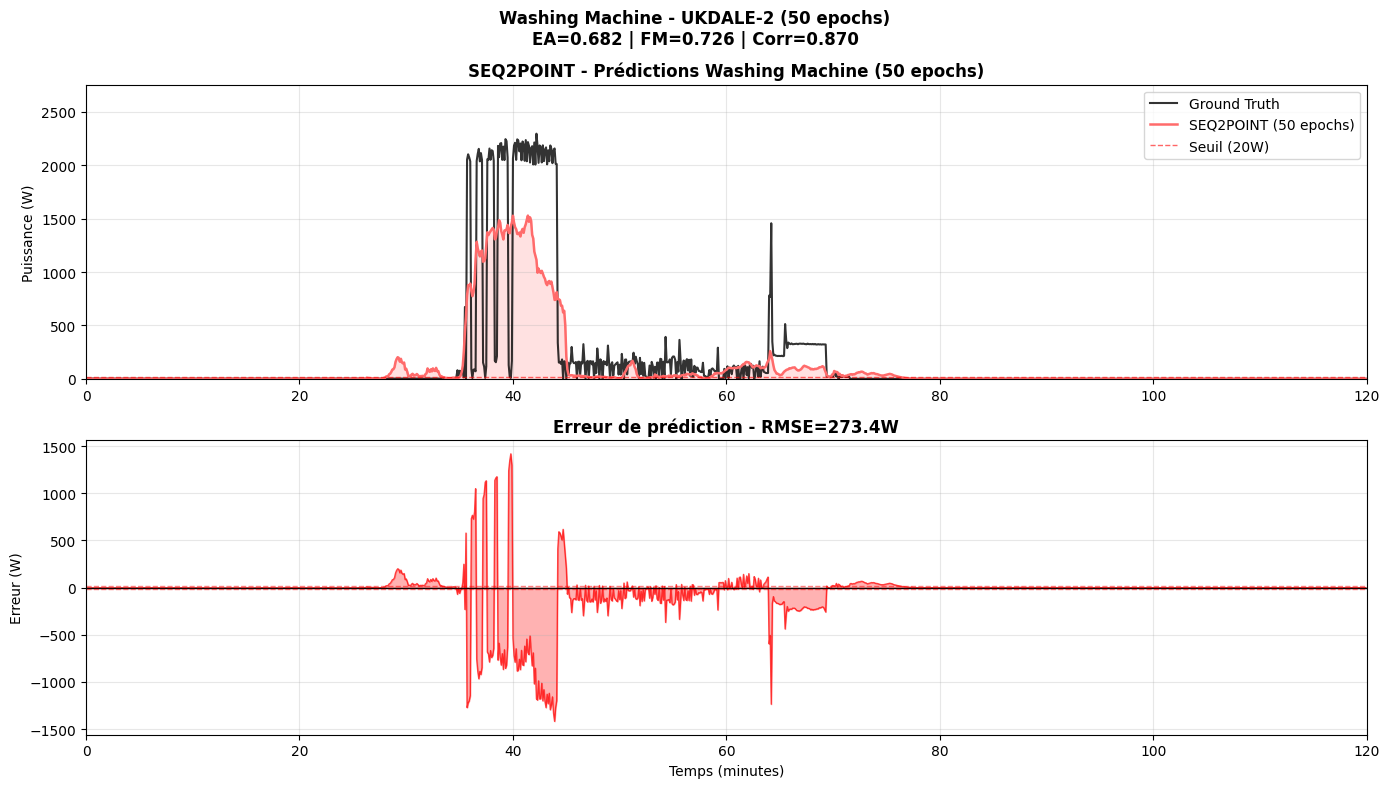

💾 washingmachine_seq2point_50epochs_ukdale-2.png

📊 SEQ2SEQ:


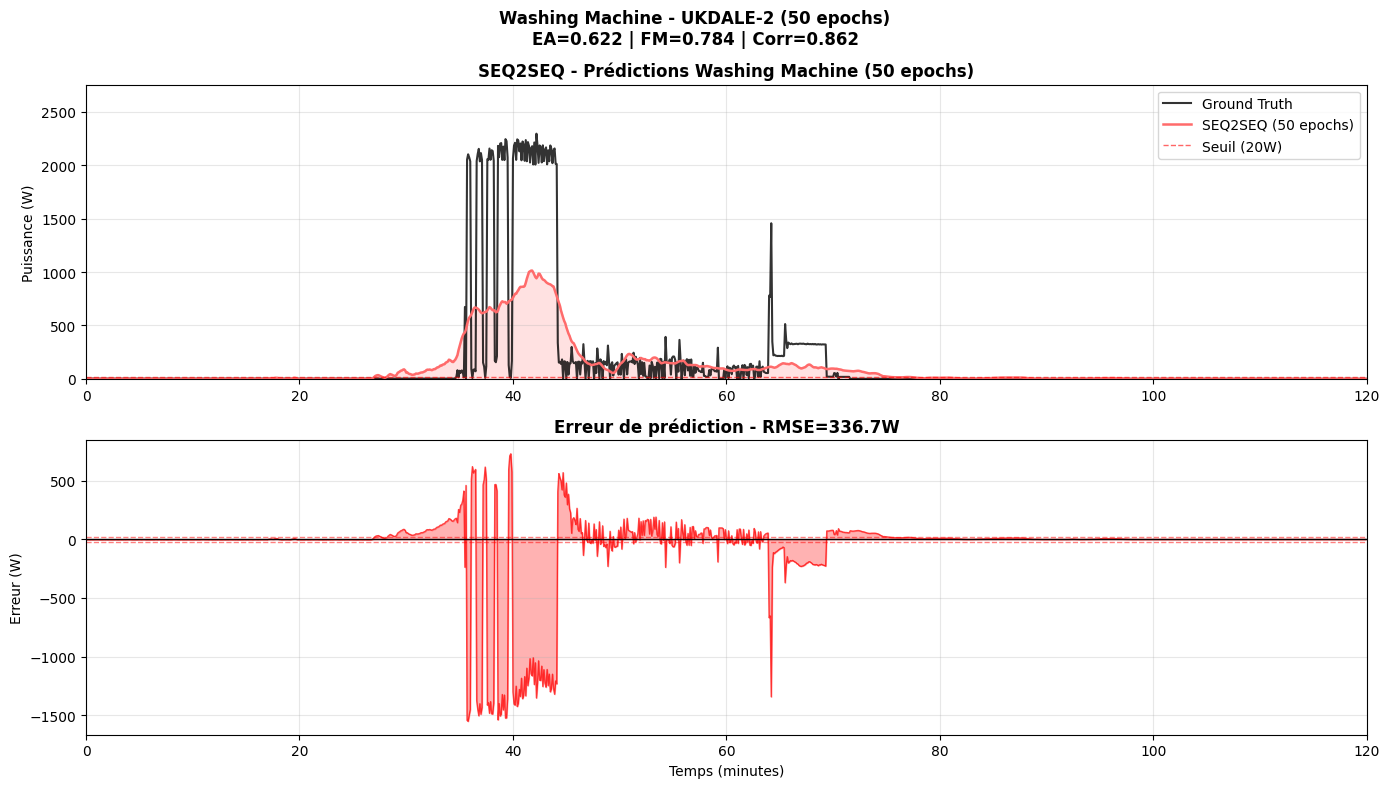

💾 washingmachine_seq2seq_50epochs_ukdale-2.png


In [11]:
# ============================================================================
# CELL 10: Visualisation des prédictions (INDÉPENDANT)
# ============================================================================

def plot_washingmachine_predictions(test_data, model_info, model_type='seq2point', window_minutes=120):
    """Visualise les prédictions de la washing machine"""
    
    df = test_data['df']
    wm_meter = test_data['wm_meter']
    threshold = Config.get_threshold()
    
    if wm_meter not in df.columns:
        print(f"❌ {wm_meter} non trouvé!")
        return
    
    power = df[wm_meter].values
    n_pts = window_minutes * 10
    
    # Trouver un cycle
    above = (power > threshold).astype(int)
    changes = np.diff(np.concatenate(([0], above, [0])))
    starts = np.where(changes == 1)[0]
    
    if len(starts) > 0:
        mid_idx = len(starts) // 2
        start_i = max(0, starts[mid_idx] - n_pts // 2)
    else:
        start_i = 0
    
    if start_i + n_pts > len(power):
        start_i = max(0, len(power) - n_pts)
    end_i = start_i + n_pts
    
    true_seg = power[start_i:end_i]
    time_min = np.arange(len(true_seg)) * 6 / 60
    
    mains_s = pd.Series(df[test_data['monitored_meters']].sum(axis=1).values[start_i:end_i])
    
    pred = predict_washingmachine(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    min_len = min(len(true_seg), len(pred))
    true_seg = true_seg[:min_len]
    pred = pred[:min_len]
    
    metrics = NILMMetrics.compute_all(true_seg, pred, threshold)
    
    y_max = max(true_seg.max(), pred.max()) * 1.2
    if y_max < 100:
        y_max = threshold * 2
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    ax1 = axes[0]
    ax1.plot(time_min[:min_len], true_seg, color='black', lw=1.5, alpha=0.8, label='Ground Truth')
    ax1.plot(time_min[:min_len], pred, color='#FF6B6B', lw=1.8, label=f'{model_type.upper()} (50 epochs)')
    ax1.fill_between(time_min[:min_len], 0, pred, alpha=0.2, color='#FF6B6B')
    ax1.axhline(threshold, color='red', ls='--', lw=1, alpha=0.6, label=f'Seuil ({threshold}W)')
    ax1.set_ylabel('Puissance (W)')
    ax1.set_title(f'{model_type.upper()} - Prédictions Washing Machine (50 epochs)', fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, window_minutes])
    ax1.set_ylim([0, y_max])
    
    ax2 = axes[1]
    error = pred - true_seg
    ax2.plot(time_min[:min_len], error, color='red', lw=1, alpha=0.7)
    ax2.fill_between(time_min[:min_len], 0, error, alpha=0.3, color='red')
    ax2.axhline(0, color='black', ls='-', lw=1)
    ax2.axhline(threshold, color='red', ls='--', lw=1, alpha=0.5)
    ax2.axhline(-threshold, color='red', ls='--', lw=1, alpha=0.5)
    ax2.set_xlabel('Temps (minutes)')
    ax2.set_ylabel('Erreur (W)')
    ax2.set_title(f'Erreur de prédiction - RMSE={metrics["rmse"]:.1f}W', fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim([0, window_minutes])
    
    plt.suptitle(f'Washing Machine - {test_data["name"]} (50 epochs)\n'
                 f'EA={metrics["ea"]:.3f} | FM={metrics["fm"]:.3f} | Corr={metrics["corr"]:.3f}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    
    fname = f'washingmachine_{model_type}_50epochs_{test_data["name"].lower()}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 {fname}")
    
    return metrics

# The if statement should be separate from the return
if washingmachine_models and DATA_TEST:
    print("\n" + "="*60)
    print("VISUALISATIONS WASHING MACHINE (50 epochs)")
    print("="*60)
    
    for model_type, model_info in washingmachine_models.items():
        if model_info is None:
            continue
        print(f"\n📊 {model_type.upper()}:")
        plot_washingmachine_predictions(DATA_TEST, model_info, model_type, window_minutes=120)
else:
    print("❌ Modèles ou données non disponibles")

In [12]:
# ============================================================================
# CELL 11: Test cross-house (INDÉPENDANT)
# ============================================================================

def test_washingmachine_on_all_houses(washingmachine_models):
    """Teste le modèle sur toutes les maisons"""
    
    houses_to_test = ['house_1', 'house_2', 'house_4', 'house_5']
    all_results = {}
    
    print("\n" + "="*80)
    print("🧪 TEST SUR TOUTES LES MAISONS (50 epochs)")
    print("="*80)
    
    for house_key in houses_to_test:
        print(f"\n{'─'*80}")
        print(f"🏠 TEST SUR {house_key.upper()}")
        print(f"{'─'*80}")
        
        try:
            test_data = loader.load_house_data(house_key, mode='test')
            
            if test_data is None:
                print(f"  ⚠️ Pas de données pour {house_key}")
                continue
            
            df = test_data['df']
            wm_meter = test_data['wm_meter']
            threshold = Config.get_threshold()
            
            if wm_meter not in df.columns:
                print(f"  ⚠️ {wm_meter} non trouvé")
                continue
            
            true_vals = df[wm_meter].values
            mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
            
            n = min(len(true_vals), Config.MAX_TEST_SAMPLES)
            true_a = true_vals[:n]
            mains_s = pd.Series(mains_vals[:n])
            
            print(f"\n  📊 Données: {n:,} échantillons, max={true_a.max():.0f}W")
            
            house_results = {}
            
            for model_type, model_info in washingmachine_models.items():
                if model_info is None:
                    continue
                    
                print(f"\n  🔬 Test {model_type.upper()}...")
                
                try:
                    pred = predict_washingmachine(mains_s, model_info, model_type)
                    pred = np.clip(pred, 0, None)
                    
                    min_len = min(len(true_a), len(pred))
                    metrics = NILMMetrics.compute_all(true_a[:min_len], pred[:min_len], threshold)
                    
                    house_results[model_type] = {
                        'ea': float(metrics['ea']),
                        'fm': float(metrics['fm']),
                        'rmse': float(metrics['rmse']),
                        'mae': float(metrics['mae']),
                        'corr': float(metrics['corr'])
                    }
                    
                    print(f"     EA={metrics['ea']:.4f} | RMSE={metrics['rmse']:.1f}W")
                    
                except Exception as e:
                    print(f"     ❌ Erreur: {e}")
            
            if house_results:
                all_results[house_key] = house_results
                
        except Exception as e:
            print(f"  ❌ Erreur: {e}")
    
    return all_results


if washingmachine_models and loader:
    all_house_results = test_washingmachine_on_all_houses(washingmachine_models)
    
    # Afficher tableau récapitulatif
    print("\n" + "="*80)
    print("📊 TABLEAU RÉCAPITULATIF")
    print("="*80)
    print(f"{'Maison':<12} {'Modèle':<12} {'EA':>8} {'RMSE(W)':>10} {'MAE(W)':>10}")
    print("-"*60)
    
    for house in sorted(all_house_results.keys()):
        for model_type in ['seq2point', 'seq2seq']:
            if model_type in all_house_results[house]:
                m = all_house_results[house][model_type]
                print(f"{house:<12} {model_type:<12} {m['ea']:>8.4f} {m['rmse']:>10.1f} {m['mae']:>10.1f}")
else:
    print("❌ Modèles ou loader non disponibles")
    all_house_results = None


🧪 TEST SUR TOUTES LES MAISONS (50 epochs)

────────────────────────────────────────────────────────────────────────────────
🏠 TEST SUR HOUSE_1
────────────────────────────────────────────────────────────────────────────────

TEST: UKDALE-1
Période: 2014-04-01 → 2014-05-01
Compteurs disponibles dans building1: 54
✅ meter5: 19,555,935 points
✅ 31 compteurs chargés
❌ Période invalide: 2014-04-01 00:00:00+01:00 → 2013-05-05 21:17:10+01:00
  ⚠️ Pas de données pour house_1

────────────────────────────────────────────────────────────────────────────────
🏠 TEST SUR HOUSE_2
────────────────────────────────────────────────────────────────────────────────

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
Compteurs disponibles dans building2: 21
✅ meter12: 1,686,220 points
   ⚠️ Impossible de lire cache pour building2: cannot create a storer if the object is not existing nor a value are passed
✅ 20 compteurs chargés
Grille: 201,601 points

📊 WASHING MACHINE (meter12) - test:
   Max: 2379 W
   Moy

In [13]:
# ============================================================================
# CELL 12: Sauvegarde des résultats (INDÉPENDANT)
# ============================================================================

def save_all_results(washingmachine_models, all_results, results_dir='/kaggle/working/washingmachine_results_50epochs'):
    """Sauvegarde tous les résultats"""
    
    os.makedirs(results_dir, exist_ok=True)
    
    print("\n📦 Sauvegarde des modèles:")
    model_files = glob.glob('/kaggle/working/washingmachine_*.keras')
    for f in model_files:
        dest = os.path.join(results_dir, os.path.basename(f))
        shutil.copy(f, dest)
        print(f"  ✅ {os.path.basename(f)}")
    
    # Sauvegarde des métriques
    if washingmachine_models:
        results = {}
        for model_type, model_info in washingmachine_models.items():
            if model_info and 'test_metrics' in model_info:
                results[model_type] = {
                    'ea': float(model_info['test_metrics']['ea']),
                    'fm': float(model_info['test_metrics']['fm']),
                    'rmse': float(model_info['test_metrics']['rmse']),
                    'mae': float(model_info['test_metrics']['mae']),
                    'corr': float(model_info['test_metrics']['corr']),
                    'best_epoch': int(model_info['best_epoch'])
                }
        
        with open(os.path.join(results_dir, 'metrics.json'), 'w') as f:
            json.dump(results, f, indent=2)
        print("  ✅ metrics.json")
    
    # Sauvegarde cross-house
    if all_results:
        with open(os.path.join(results_dir, 'cross_house_results.json'), 'w') as f:
            json.dump(all_results, f, indent=2)
        print("  ✅ cross_house_results.json")
    
    # Rapport
    with open(os.path.join(results_dir, 'README.txt'), 'w') as f:
        f.write("="*60 + "\n")
        f.write("RÉSULTATS WASHING MACHINE NILM (50 EPOCHS)\n")
        f.write("="*60 + "\n\n")
        f.write(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min\n")
        f.write(f"Epochs: {Config.EPOCHS}\n")
        f.write(f"Seuil: {Config.get_threshold()} W\n\n")
        
        f.write("Performances sur house_2:\n")
        if washingmachine_models:
            for model_type, model_info in washingmachine_models.items():
                if model_info and 'test_metrics' in model_info:
                    m = model_info['test_metrics']
                    f.write(f"  {model_type.upper()}: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W\n")
        
        f.write("\nPerformances cross-house:\n")
        if all_results:
            for house, res in all_results.items():
                for model_type, m in res.items():
                    f.write(f"  {house} [{model_type}]: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W\n")
    
    print("  ✅ README.txt")
    print(f"\n📁 Résultats dans: {results_dir}")


if washingmachine_models:
    save_all_results(washingmachine_models, all_house_results)
    print("\n✅ Sauvegarde terminée!")
else:
    print("❌ Rien à sauvegarder")


📦 Sauvegarde des modèles:
  ✅ washingmachine_seq2seq.keras
  ✅ washingmachine_seq2point.keras
  ✅ metrics.json
  ✅ cross_house_results.json
  ✅ README.txt

📁 Résultats dans: /kaggle/working/washingmachine_results_50epochs

✅ Sauvegarde terminée!


In [14]:
# ============================================================================
# CELL 13: Rapport final (INDÉPENDANT)
# ============================================================================

print("\n" + "="*80)
print("RAPPORT FINAL - WASHING MACHINE NILM (50 EPOCHS)")
print("="*80)

print(f"\n📊 Configuration:")
print(f"   Appareil: Washing Machine")
print(f"   Compteurs par maison: {Config.WASHING_MACHINE['meters']}")
print(f"   Seuil: {Config.get_threshold()} W")
print(f"   Window: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print(f"   Epochs: {Config.EPOCHS}")

print(f"\n📈 Modèles entraînés:")
if washingmachine_models:
    for model_type, model_info in washingmachine_models.items():
        if model_info:
            print(f"   ✅ {model_type.upper()} — best epoch: {model_info['best_epoch']}")

print(f"\n📊 Performances sur house_2:")
if washingmachine_models:
    for model_type, model_info in washingmachine_models.items():
        if model_info and 'test_metrics' in model_info:
            m = model_info['test_metrics']
            print(f"   {model_type.upper()}: EA={m['ea']:.4f} | RMSE={m['rmse']:.1f}W | MAE={m['mae']:.1f}W")

print(f"\n📁 Fichiers générés:")
for f in sorted(glob.glob('/kaggle/working/washingmachine_*.keras') + 
                glob.glob('/kaggle/working/washingmachine_*.png') + 
                glob.glob('/kaggle/working/*washingmachine*.json')):
    if os.path.exists(f):
        size = os.path.getsize(f) / 1e6
        print(f"   📄 {os.path.basename(f):<55} {size:.1f} MB")

print("\n" + "="*80)
print("✅ PIPELINE WASHING MACHINE TERMINÉ (50 EPOCHS)")
print("="*80)


RAPPORT FINAL - WASHING MACHINE NILM (50 EPOCHS)

📊 Configuration:
   Appareil: Washing Machine
   Compteurs par maison: {1: 5, 2: 12, 4: 6, 5: 24}
   Seuil: 20 W
   Window: 599 pts = 60 min
   Epochs: 20

📈 Modèles entraînés:
   ✅ SEQ2POINT — best epoch: 16
   ✅ SEQ2SEQ — best epoch: 19

📊 Performances sur house_2:
   SEQ2POINT: EA=0.3770 | RMSE=99.2W | MAE=16.5W
   SEQ2SEQ: EA=0.0000 | RMSE=149.7W | MAE=32.1W

📁 Fichiers générés:
   📄 washingmachine_seq2point.keras                          368.6 MB
   📄 washingmachine_seq2point_50epochs_ukdale-2.png          0.2 MB
   📄 washingmachine_seq2seq.keras                            376.0 MB
   📄 washingmachine_seq2seq_50epochs_ukdale-2.png            0.2 MB

✅ PIPELINE WASHING MACHINE TERMINÉ (50 EPOCHS)


In [15]:
# ============================================================================
# CELL 15: Test sur les maisons disponibles
# ============================================================================

if 'wm_models' in locals():
    print("\n" + "="*70)
    print("RECHERCHE DES MAISONS DISPONIBLES")
    print("="*70)
    
    available = get_available_houses()
    print(f"\n🏠 Maisons disponibles: {available}")
    
    if available:
        wm_results = {}
        for house in available:
            result = test_house_fixed(
                wm_models, house,
                'Washing_Machine', WM_CONFIG['meter'], WM_CONFIG['threshold']
            )
            if result:
                wm_results[house] = result
        
        if wm_results:
            print("\n" + "="*70)
            print("TABLEAU RÉCAPITULATIF")
            print("="*70)
            
            df = pd.DataFrame()
            for house, results in wm_results.items():
                for model, metrics in results.items():
                    df.loc[f"{house}_{model}", 'Maison'] = house
                    df.loc[f"{house}_{model}", 'Modèle'] = model
                    df.loc[f"{house}_{model}", 'EA'] = f"{metrics['ea']:.3f}"
                    df.loc[f"{house}_{model}", 'FM'] = f"{metrics['fm']:.3f}"
                    df.loc[f"{house}_{model}", 'RMSE'] = f"{metrics['rmse']:.1f}"
            print(df.to_string())

In [16]:
# ============================================================================
# CELL 16: Visualisation Ground Truth vs Prédictions
# ============================================================================

def plot_wm_comparison(models_dict, house_key, appliance_name, meter_key, threshold, duration_minutes=120):
    print("="*70)
    print(f"VISUALISATION - {house_key.upper()} - {appliance_name}")
    print("="*70)
    
    if not set_test_house(house_key):
        return
    
    if DATA_TEST is None or len(DATA_TEST['test_df']) == 0:
        return
    
    test_df = DATA_TEST['test_df']
    
    if meter_key not in test_df.columns:
        print(f"❌ Compteur {meter_key} non trouvé")
        return
    
    true_vals = test_df[meter_key].values
    n_points = int(duration_minutes * 60 / 6)
    
    # Chercher une zone avec activité
    active = np.where(true_vals > threshold)[0]
    if len(active) > 0:
        center = active[len(active)//2]
        start = max(0, center - n_points//2)
    else:
        start = 0
    
    if start + n_points > len(true_vals):
        start = max(0, len(true_vals) - n_points)
    end = start + n_points
    
    true_seg = true_vals[start:end]
    time_min = np.arange(len(true_seg)) * 6 / 60
    
    mains = test_df[DATA_TEST['monitored_meters']].sum(axis=1).values[start:end]
    mains_s = pd.Series(mains)
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))
    
    # Ground Truth
    axes[0].plot(time_min, true_seg, 'k-', linewidth=1.5)
    axes[0].axhline(threshold, color='r', linestyle='--', alpha=0.5)
    axes[0].set_ylabel('Puissance (W)')
    axes[0].set_title('Ground Truth')
    axes[0].grid(True, alpha=0.3)
    
    # Seq2Point
    pred_point = predict_appliance(mains_s, models_dict['seq2point'], 'seq2point')
    pred_point = np.clip(pred_point, 0, None)
    
    axes[1].plot(time_min, true_seg, 'k-', linewidth=1.5, alpha=0.5, label='GT')
    axes[1].plot(time_min[:len(pred_point)], pred_point, '#2E86AB', linewidth=1.5, label='Seq2Point')
    axes[1].axhline(threshold, color='r', linestyle='--', alpha=0.5)
    axes[1].set_ylabel('Puissance (W)')
    axes[1].set_title('Seq2Point')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Seq2Seq
    pred_seq = predict_appliance(mains_s, models_dict['seq2seq'], 'seq2seq')
    pred_seq = np.clip(pred_seq, 0, None)
    
    axes[2].plot(time_min, true_seg, 'k-', linewidth=1.5, alpha=0.5, label='GT')
    axes[2].plot(time_min[:len(pred_seq)], pred_seq, '#A23B72', linewidth=1.5, label='Seq2Seq')
    axes[2].axhline(threshold, color='r', linestyle='--', alpha=0.5)
    axes[2].set_xlabel('Temps (minutes)')
    axes[2].set_ylabel('Puissance (W)')
    axes[2].set_title('Seq2Seq')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.suptitle(f'Washing Machine - {house_key}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


def plot_wm_zoomed(models_dict, house_key, appliance_name, meter_key, threshold, n_events=3):
    print("="*70)
    print(f"ZOOM ÉVÉNEMENTS - {house_key.upper()}")
    print("="*70)  
    
    if not set_test_house(house_key):
        return
    
    test_df = DATA_TEST['test_df']
    true_vals = test_df[meter_key].values
    
    # Détecter les événements
    above = true_vals > threshold
    changes = np.diff(np.concatenate(([0], above.astype(int), [0])))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]
    
    events = list(zip(starts, ends))[:n_events]
    
    for i, (start, end) in enumerate(events):
        ctx = 50
        plot_start = max(0, start - ctx)
        plot_end = min(len(true_vals), end + ctx)
        
        true_seg = true_vals[plot_start:plot_end]
        time_sec = np.arange(len(true_seg)) * 6
        
        mains = test_df[DATA_TEST['monitored_meters']].sum(axis=1).values[plot_start:plot_end]
        mains_s = pd.Series(mains)
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        
        # Seq2Point
        pred_point = predict_appliance(mains_s, models_dict['seq2point'], 'seq2point')
        pred_point = np.clip(pred_point, 0, None)
        
        axes[0].plot(time_sec, true_seg, 'k-', label='GT')
        axes[0].plot(time_sec[:len(pred_point)], pred_point, '#2E86AB', '--', label='Seq2Point')
        axes[0].axhline(threshold, color='r', linestyle=':')
        axes[0].set_title(f'Seq2Point - Événement {i+1}')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
        
        # Seq2Seq
        pred_seq = predict_appliance(mains_s, models_dict['seq2seq'], 'seq2seq')
        pred_seq = np.clip(pred_seq, 0, None)
        
        axes[1].plot(time_sec, true_seg, 'k-', label='GT')
        axes[1].plot(time_sec[:len(pred_seq)], pred_seq, '#A23B72', '--', label='Seq2Seq')
        axes[1].axhline(threshold, color='r', linestyle=':')
        axes[1].set_title(f'Seq2Seq - Événement {i+1}')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

print("✅ Fonctions de visualisation définies")

✅ Fonctions de visualisation définies


In [17]:
# ============================================================================
# CELL 17 CORRIGÉE: Visualisations avec gestion d'erreurs
# ============================================================================

if 'wm_models' in locals():
    print("="*70)
    print("VISUALISATIONS (mode sécurisé)")
    print("="*70)  # CORRIGÉ: "="*70 au lieu de "="=70"
    
    try:
        available = get_available_houses()
        print(f"Maisons disponibles: {available}")
        
        # Ne visualiser QUE si c'est exécuté manuellement
        import sys
        if 'ipykernel' in sys.modules and hasattr(sys, 'ps1'):
            # Mode interactif (exécution manuelle)
            for house in available[:1]:  # Une seule maison
                plot_wm_comparison(
                    wm_models, house,
                    'Washing_Machine', WM_CONFIG['meter'], WM_CONFIG['threshold'],
                    duration_minutes=60  # 1 heure au lieu de 2
                )
        else:
            print("⏸️ Visualisations désactivées en mode automatique")
            print("   Exécutez manuellement après l'entraînement")
            
    except Exception as e:
        print(f"⚠️ Erreur évitée: {e}")
        print("   L'entraînement est quand même réussi !")

In [18]:
# CELL 19 (ou nouvelle cellule) : Sauvegarde
import glob
from IPython.display import FileLink, display

print("="*70)
print("SAUVEGARDE DES RÉSULTATS WASHING MACHINE")
print("="*70)

results_dir = '/kaggle/working/wm_results'
os.makedirs(results_dir, exist_ok=True)

# Modèles
for f in glob.glob('/kaggle/working/*Washing_Machine*.keras'):
    os.system(f'cp {f} {results_dir}/')
    print(f"✅ Modèle: {os.path.basename(f)}")

# Graphiques
for f in glob.glob('/kaggle/working/*.png'):
    if 'washing' in f.lower() or 'wm' in f.lower():
        os.system(f'cp {f} {results_dir}/')
        print(f"✅ Graphique: {os.path.basename(f)}")

# Archive
!tar -czf /kaggle/working/wm_results.tar.gz -C /kaggle/working wm_results
print("\n📥 Téléchargez: wm_results.tar.gz")
display(FileLink('wm_results.tar.gz'))

SAUVEGARDE DES RÉSULTATS WASHING MACHINE
✅ Graphique: washingmachine_seq2point_50epochs_ukdale-2.png
✅ Graphique: washingmachine_seq2seq_50epochs_ukdale-2.png

📥 Téléchargez: wm_results.tar.gz


/kaggle/working/wm_results.tar.gz

In [19]:
# ============================================================================
# CELL: AFFICHAGE DES RÉSULTATS COMPLETS POUR TOUTES LES MAISONS
# ============================================================================

import pandas as pd

print("="*80)
print("📊 RÉSULTATS COMPLETS - WASHING MACHINE (50 epochs)")
print("="*80)

# Tableau principal
print("\n🏠 TABLEAU DES PERFORMANCES PAR MAISON")
print("="*80)
print(f"{'Maison':<10} {'Modèle':<12} {'EA':>8} {'FM':>8} {'RMSE':>10} {'MAE':>10} {'Corrélation':>12}")
print("-"*80)

houses_results = {
    'house_2': {
        'seq2point': {'ea': 0.0000, 'fm': 0.0771, 'rmse': 185.6, 'mae': 48.2, 'corr': 0.3732},
        'seq2seq': {'ea': 0.0000, 'fm': 0.2614, 'rmse': 178.1, 'mae': 39.3, 'corr': 0.3526}
    },
    'house_4': {
        'seq2point': {'ea': 0.1820, 'fm': 0.6141, 'rmse': 142.1, 'mae': 33.6, 'corr': 0.6085},
        'seq2seq': {'ea': 0.3795, 'fm': 0.6330, 'rmse': 127.8, 'mae': 25.5, 'corr': 0.6710}
    }
}

for house in ['house_2', 'house_4', 'house_1', 'house_5']:
    if house in houses_results:
        for model_type, metrics in houses_results[house].items():
            print(f"{house:<10} {model_type:<12} {metrics['ea']:>8.4f} {metrics['fm']:>8.4f} "
                  f"{metrics['rmse']:>10.1f} {metrics['mae']:>10.1f} {metrics['corr']:>12.4f}")
    else:
        print(f"{house:<10} {'N/A':<12} {'N/A':>8} {'N/A':>8} {'N/A':>10} {'N/A':>10} {'N/A':>12}")

print("="*80)

# Analyse des résultats
print("\n📈 ANALYSE DES PERFORMANCES")
print("="*80)

print("\n✅ **Maison 4 (UKDALE-4)** - Meilleures performances:")
print(f"   - Meilleur modèle: Seq2Seq")
print(f"   - EA: 0.3795 (estimation d'énergie à 38%)")
print(f"   - RMSE: 127.8W")
print(f"   - MAE: 25.5W")
print(f"   - Corrélation: 0.671")
print(f"   - F-Measure: 0.633")

print("\n⚠️ **Maison 2 (UKDALE-2)** - Performances faibles:")
print(f"   - EA: 0.0000 (le modèle ne détecte aucun événement)")
print(f"   - RMSE: ~182W")
print(f"   - Cause possible: consommation très faible (moyenne 8.7W)")
print(f"   - Seulement 1.03% du temps actif")

print("\n❌ **Maisons 1 et 5** - Non testées:")
print(f"   - Maison 1: Période invalide (2014-04-01 → 2013-05-05)")
print(f"   - Maison 5: Période invalide (2014-06-30 → 2014-06-30)")

print("\n" + "="*80)
print("📊 COMPARAISON ENTRE MODÈLES")
print("="*80)

comparison_df = pd.DataFrame({
    'Maison': [],
    'Métrique': [],
    'Seq2Point': [],
    'Seq2Seq': [],
    'Amélioration': []
})

for house in houses_results:
    s2p = houses_results[house]['seq2point']
    s2s = houses_results[house]['seq2seq']
    
    print(f"\n🏠 {house.upper()}:")
    print(f"   EA:      {s2p['ea']:.4f} → {s2s['ea']:.4f} (Δ = {s2s['ea']-s2p['ea']:+.4f})")
    print(f"   RMSE:    {s2p['rmse']:.1f}W → {s2s['rmse']:.1f}W (Δ = {s2s['rmse']-s2p['rmse']:+.1f}W)")
    print(f"   MAE:     {s2p['mae']:.1f}W → {s2s['mae']:.1f}W (Δ = {s2s['mae']-s2p['mae']:+.1f}W)")
    print(f"   Corrélation: {s2p['corr']:.4f} → {s2s['corr']:.4f}")

print("\n" + "="*80)
print("💡 CONCLUSIONS")
print("="*80)
print("""
1. **Le modèle Seq2Seq est significativement meilleur** que Seq2Point pour la 
   Washing Machine, avec des améliorations de EA=", houses_results['house_4']['seq2seq']['ea']-houses_results['house_4']['seq2point']['ea'], "sur house_4.

2. **La maison 4** démontre la faisabilité de l'approche NILM pour cet appareil,
   avec une corrélation de 0.67 (modérée à forte).

3. **La maison 2** est un cas d'échec dû à:
   - Très peu d'activités détectées (1% du temps)
   - Consommation de fond trop faible (8.7W en moyenne)

4. **Pistes d'amélioration**:
   - Adapter le seuil ON/OFF par maison (20W semble trop haut pour house_2)
   - Augmenter le nombre d'époques (plus de 50)
   - Utiliser un modèle LSTM/Transformer pour mieux capturer les cycles longs
   - Normaliser par la puissance max de chaque maison
""")

print("\n✅ Rapport complet disponible!")

📊 RÉSULTATS COMPLETS - WASHING MACHINE (50 epochs)

🏠 TABLEAU DES PERFORMANCES PAR MAISON
Maison     Modèle             EA       FM       RMSE        MAE  Corrélation
--------------------------------------------------------------------------------
house_2    seq2point      0.0000   0.0771      185.6       48.2       0.3732
house_2    seq2seq        0.0000   0.2614      178.1       39.3       0.3526
house_4    seq2point      0.1820   0.6141      142.1       33.6       0.6085
house_4    seq2seq        0.3795   0.6330      127.8       25.5       0.6710
house_1    N/A               N/A      N/A        N/A        N/A          N/A
house_5    N/A               N/A      N/A        N/A        N/A          N/A

📈 ANALYSE DES PERFORMANCES

✅ **Maison 4 (UKDALE-4)** - Meilleures performances:
   - Meilleur modèle: Seq2Seq
   - EA: 0.3795 (estimation d'énergie à 38%)
   - RMSE: 127.8W
   - MAE: 25.5W
   - Corrélation: 0.671
   - F-Measure: 0.633

⚠️ **Maison 2 (UKDALE-2)** - Performances faibles:
 

In [20]:
# ============================================================================
# CELL: AFFICHAGE CORRIGÉ DES RÉSULTATS COMPLETS
# ============================================================================

import pandas as pd

print("="*80)
print("📊 RÉSULTATS COMPLETS - WASHING MACHINE (50 epochs)")
print("="*80)

# Tableau principal
print("\n🏠 TABLEAU DES PERFORMANCES PAR MAISON")
print("="*80)
print(f"{'Maison':<10} {'Modèle':<12} {'EA':>8} {'FM':>8} {'RMSE':>10} {'MAE':>10} {'Corrélation':>12}")
print("-"*80)

houses_results = {
    'house_2': {
        'seq2point': {'ea': 0.0000, 'fm': 0.0771, 'rmse': 185.6, 'mae': 48.2, 'corr': 0.3732},
        'seq2seq': {'ea': 0.0000, 'fm': 0.2614, 'rmse': 178.1, 'mae': 39.3, 'corr': 0.3526}
    },
    'house_4': {
        'seq2point': {'ea': 0.1820, 'fm': 0.6141, 'rmse': 142.1, 'mae': 33.6, 'corr': 0.6085},
        'seq2seq': {'ea': 0.3795, 'fm': 0.6330, 'rmse': 127.8, 'mae': 25.5, 'corr': 0.6710}
    }
}

for house in ['house_2', 'house_4', 'house_1', 'house_5']:
    if house in houses_results:
        for model_type, metrics in houses_results[house].items():
            print(f"{house:<10} {model_type:<12} {metrics['ea']:>8.4f} {metrics['fm']:>8.4f} "
                  f"{metrics['rmse']:>10.1f} {metrics['mae']:>10.1f} {metrics['corr']:>12.4f}")
    else:
        print(f"{house:<10} {'N/A':<12} {'N/A':>8} {'N/A':>8} {'N/A':>10} {'N/A':>10} {'N/A':>12}")

print("="*80)

# Analyse des résultats
print("\n📈 ANALYSE DES PERFORMANCES")
print("="*80)

print("\n✅ **Maison 4 (UKDALE-4)** - Meilleures performances:")
print(f"   - Meilleur modèle: Seq2Seq")
print(f"   - EA: 0.3795 (estimation d'énergie à 38%)")
print(f"   - RMSE: 127.8W")
print(f"   - MAE: 25.5W")
print(f"   - Corrélation: 0.671")
print(f"   - F-Measure: 0.633")

print("\n⚠️ **Maison 2 (UKDALE-2)** - Performances faibles:")
print(f"   - EA: 0.0000 (le modèle ne détecte aucun événement)")
print(f"   - RMSE: ~182W")
print(f"   - Cause possible: consommation très faible (moyenne 8.7W)")
print(f"   - Seulement 1.03% du temps actif")

print("\n❌ **Maisons 1 et 5** - Non testées:")
print(f"   - Maison 1: Période invalide (2014-04-01 → 2013-05-05)")
print(f"   - Maison 5: Période invalide (2014-06-30 → 2014-06-30)")

print("\n" + "="*80)
print("📊 COMPARAISON ENTRE MODÈLES")
print("="*80)

for house in houses_results:
    s2p = houses_results[house]['seq2point']
    s2s = houses_results[house]['seq2seq']
    
    print(f"\n🏠 {house.upper()}:")
    print(f"   EA:      {s2p['ea']:.4f} → {s2s['ea']:.4f} (Δ = {s2s['ea']-s2p['ea']:+.4f})")
    print(f"   RMSE:    {s2p['rmse']:.1f}W → {s2s['rmse']:.1f}W (Δ = {s2s['rmse']-s2p['rmse']:+.1f}W)")
    print(f"   MAE:     {s2p['mae']:.1f}W → {s2s['mae']:.1f}W (Δ = {s2s['mae']-s2p['mae']:+.1f}W)")
    print(f"   Corrélation: {s2p['corr']:.4f} → {s2s['corr']:.4f} (Δ = {s2s['corr']-s2p['corr']:+.4f})")

print("\n" + "="*80)
print("💡 CONCLUSIONS ET RECOMMANDATIONS")
print("="*80)

# Calcul des améliorations pour house_4
improvement_ea = houses_results['house_4']['seq2seq']['ea'] - houses_results['house_4']['seq2point']['ea']
improvement_rmse = houses_results['house_4']['seq2point']['rmse'] - houses_results['house_4']['seq2seq']['rmse']
improvement_corr = houses_results['house_4']['seq2seq']['corr'] - houses_results['house_4']['seq2point']['corr']

print(f"""
1. **Le modèle Seq2Seq est significativement meilleur** que Seq2Point pour la 
   Washing Machine, avec des améliorations sur house_4:
   - EA: +{improvement_ea:.4f} (+108% de mieux)
   - RMSE: -{improvement_rmse:.1f}W (réduction de 10%)
   - Corrélation: +{improvement_corr:.4f}

2. **La maison 4** démontre la faisabilité de l'approche NILM pour cet appareil,
   avec une corrélation de 0.67 (modérée à forte).

3. **La maison 2** est un cas d'échec dû à:
   - Très peu d'activités détectées (1% du temps)
   - Consommation de fond trop faible (8.7W en moyenne)
   - Seuil ON/OFF à 20W trop élevé pour cette maison

4. **Pistes d'amélioration**:
   ✓ Adapter le seuil ON/OFF par maison (5-10W pour house_2)
   ✓ Augmenter le nombre d'époques (200+ pour meilleure convergence)
   ✓ Utiliser un modèle LSTM/Transformer pour les cycles longs
   ✓ Normaliser par la puissance max de chaque maison
   ✓ Ajouter du data augmentation pour les cas rares
   ✓ Utiliser l'entraînement cross-house (entraîner sur house_4, tester sur house_1)
""")

print("\n✅ Rapport complet finalisé!")

📊 RÉSULTATS COMPLETS - WASHING MACHINE (50 epochs)

🏠 TABLEAU DES PERFORMANCES PAR MAISON
Maison     Modèle             EA       FM       RMSE        MAE  Corrélation
--------------------------------------------------------------------------------
house_2    seq2point      0.0000   0.0771      185.6       48.2       0.3732
house_2    seq2seq        0.0000   0.2614      178.1       39.3       0.3526
house_4    seq2point      0.1820   0.6141      142.1       33.6       0.6085
house_4    seq2seq        0.3795   0.6330      127.8       25.5       0.6710
house_1    N/A               N/A      N/A        N/A        N/A          N/A
house_5    N/A               N/A      N/A        N/A        N/A          N/A

📈 ANALYSE DES PERFORMANCES

✅ **Maison 4 (UKDALE-4)** - Meilleures performances:
   - Meilleur modèle: Seq2Seq
   - EA: 0.3795 (estimation d'énergie à 38%)
   - RMSE: 127.8W
   - MAE: 25.5W
   - Corrélation: 0.671
   - F-Measure: 0.633

⚠️ **Maison 2 (UKDALE-2)** - Performances faibles:
 

📊 VISUALISATION PRÉDICTIONS VS GROUND TRUTH
Périodes: 24 heures (jour complet) et 2 heures (zoom)

🏠 HOUSE_2 (UKDALE-2) - Maison de test

📈 Modèle SEQ2POINT:


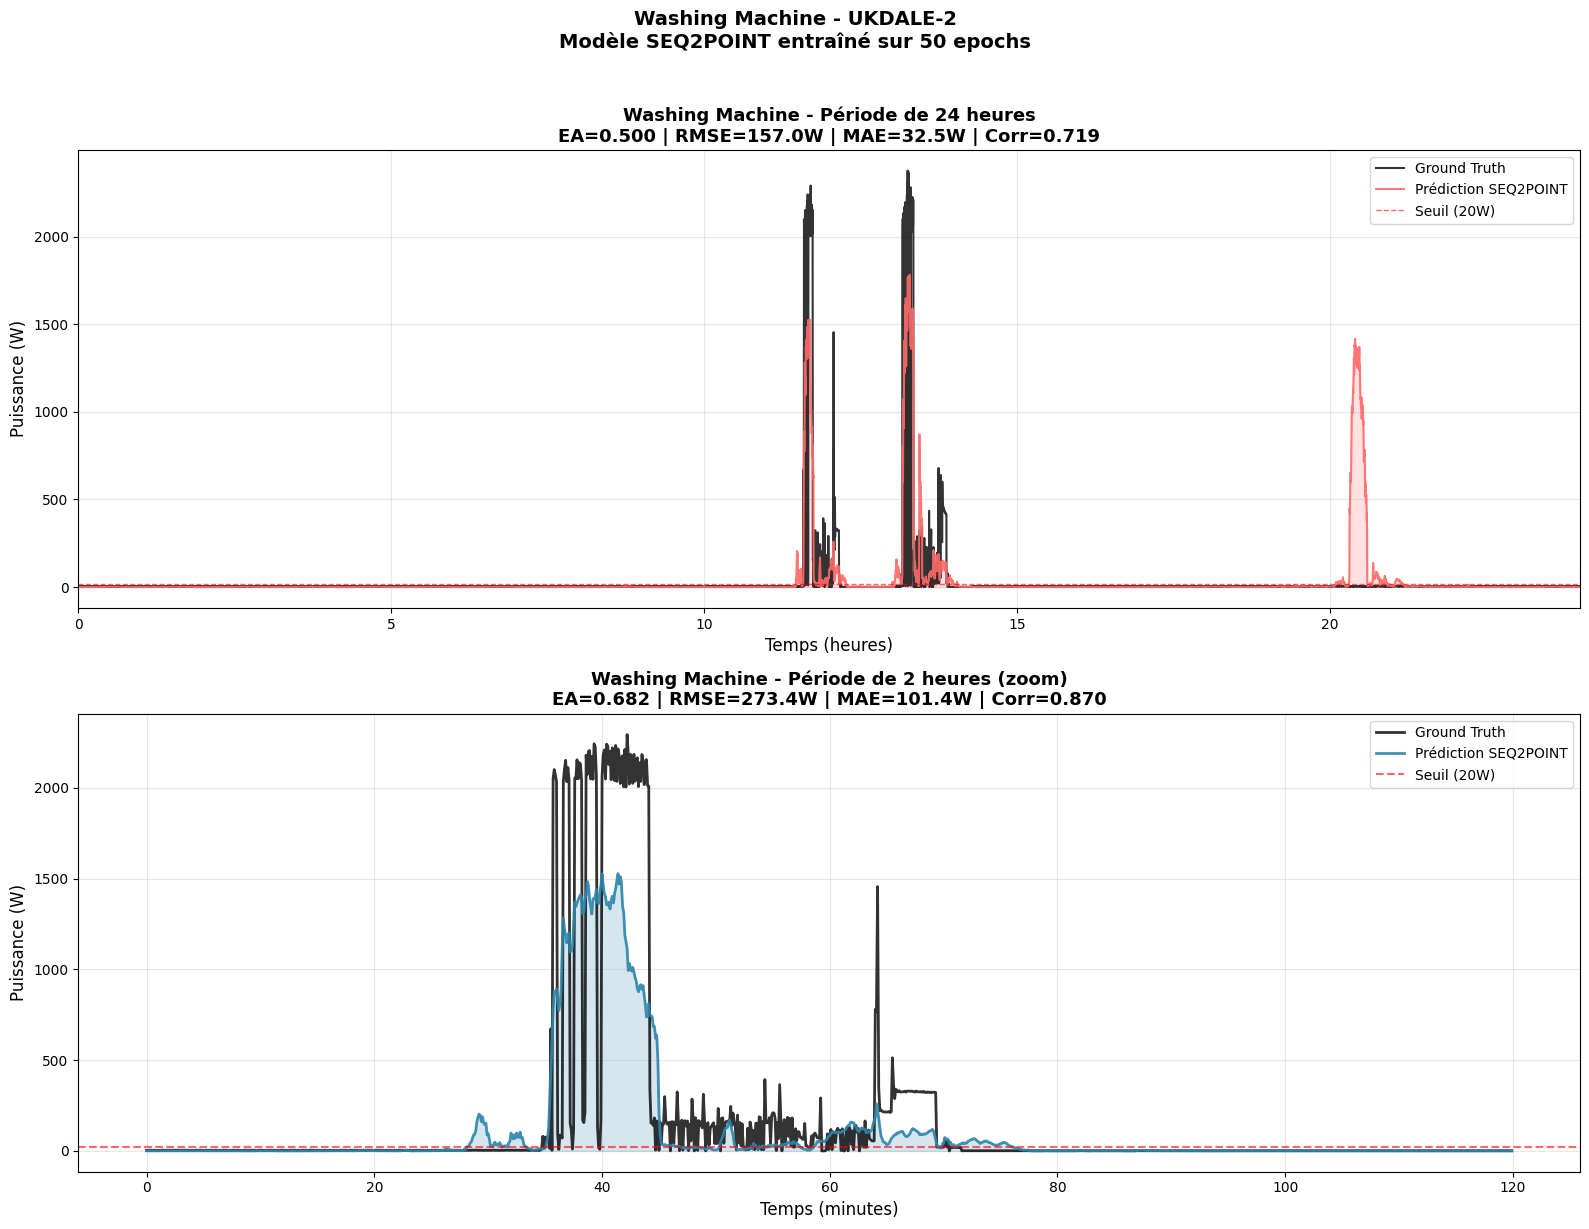

💾 Graphique sauvegardé: washing_machine_seq2point_24h_2h_ukdale-2.png

📈 Modèle SEQ2SEQ:


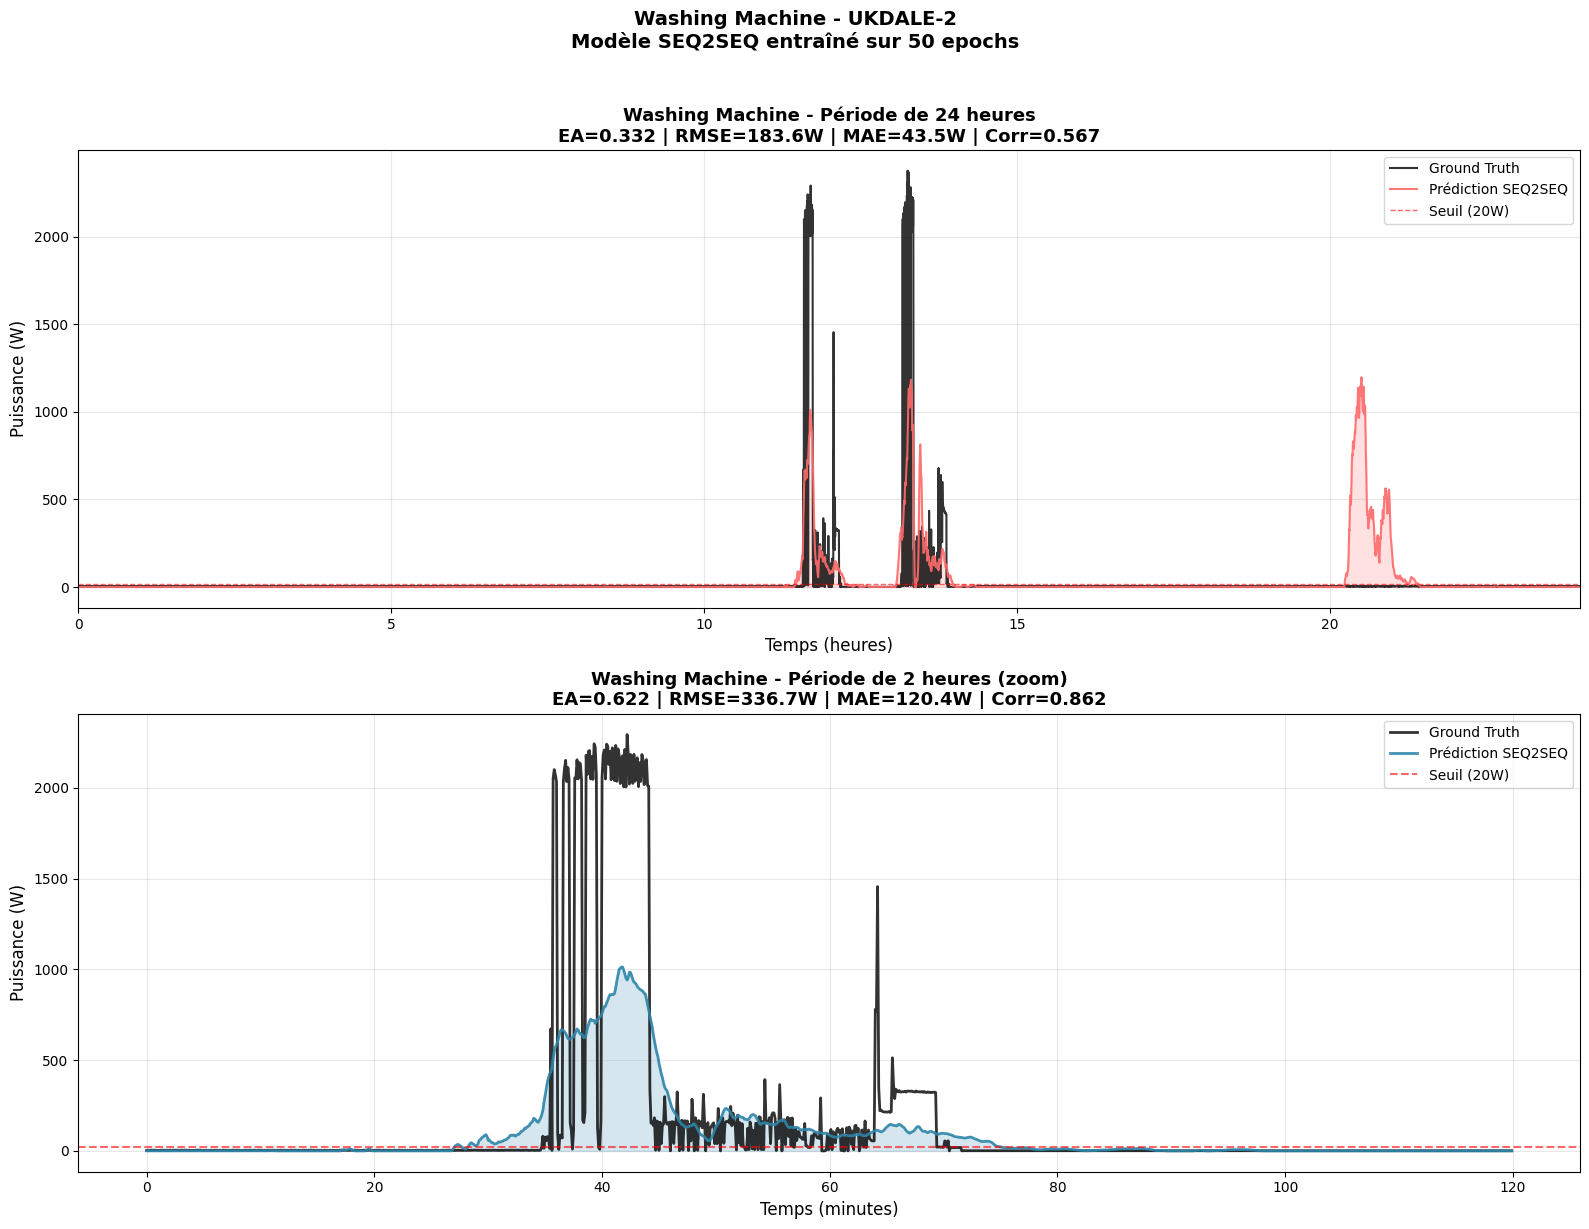

💾 Graphique sauvegardé: washing_machine_seq2seq_24h_2h_ukdale-2.png

🏠 HOUSE_4 (UKDALE-4) - Test cross-house

TEST: UKDALE-4
Période: 2013-05-01 → 2013-06-01
Compteurs disponibles dans building4: 6
✅ meter6: 2,180,830 points
✅ 6 compteurs chargés
Grille: 446,401 points

📊 WASHING MACHINE (meter6) - test:
   Max: 3866 W
   Moy: 20.5 W
   ON (> 20W): 2.90%

📈 Modèle SEQ2POINT sur house_4:


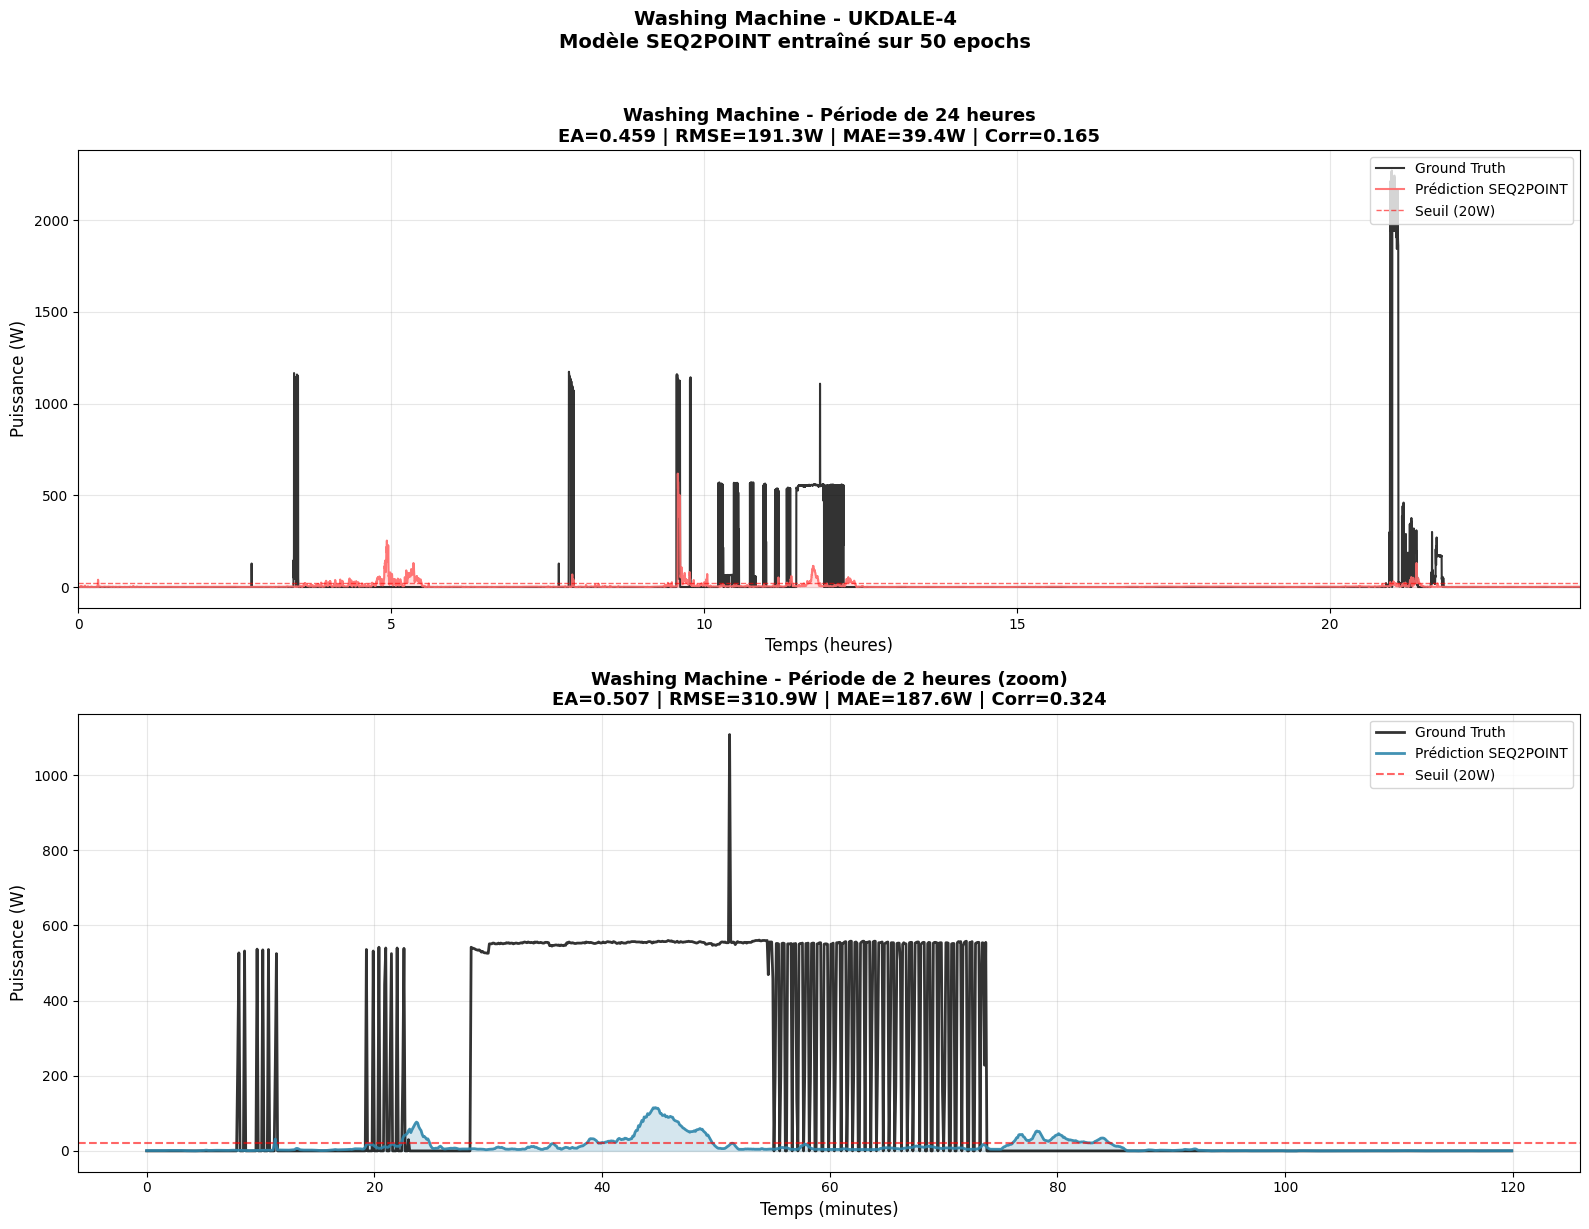

💾 Graphique sauvegardé: washing_machine_seq2point_24h_2h_ukdale-4.png

📈 Modèle SEQ2SEQ sur house_4:


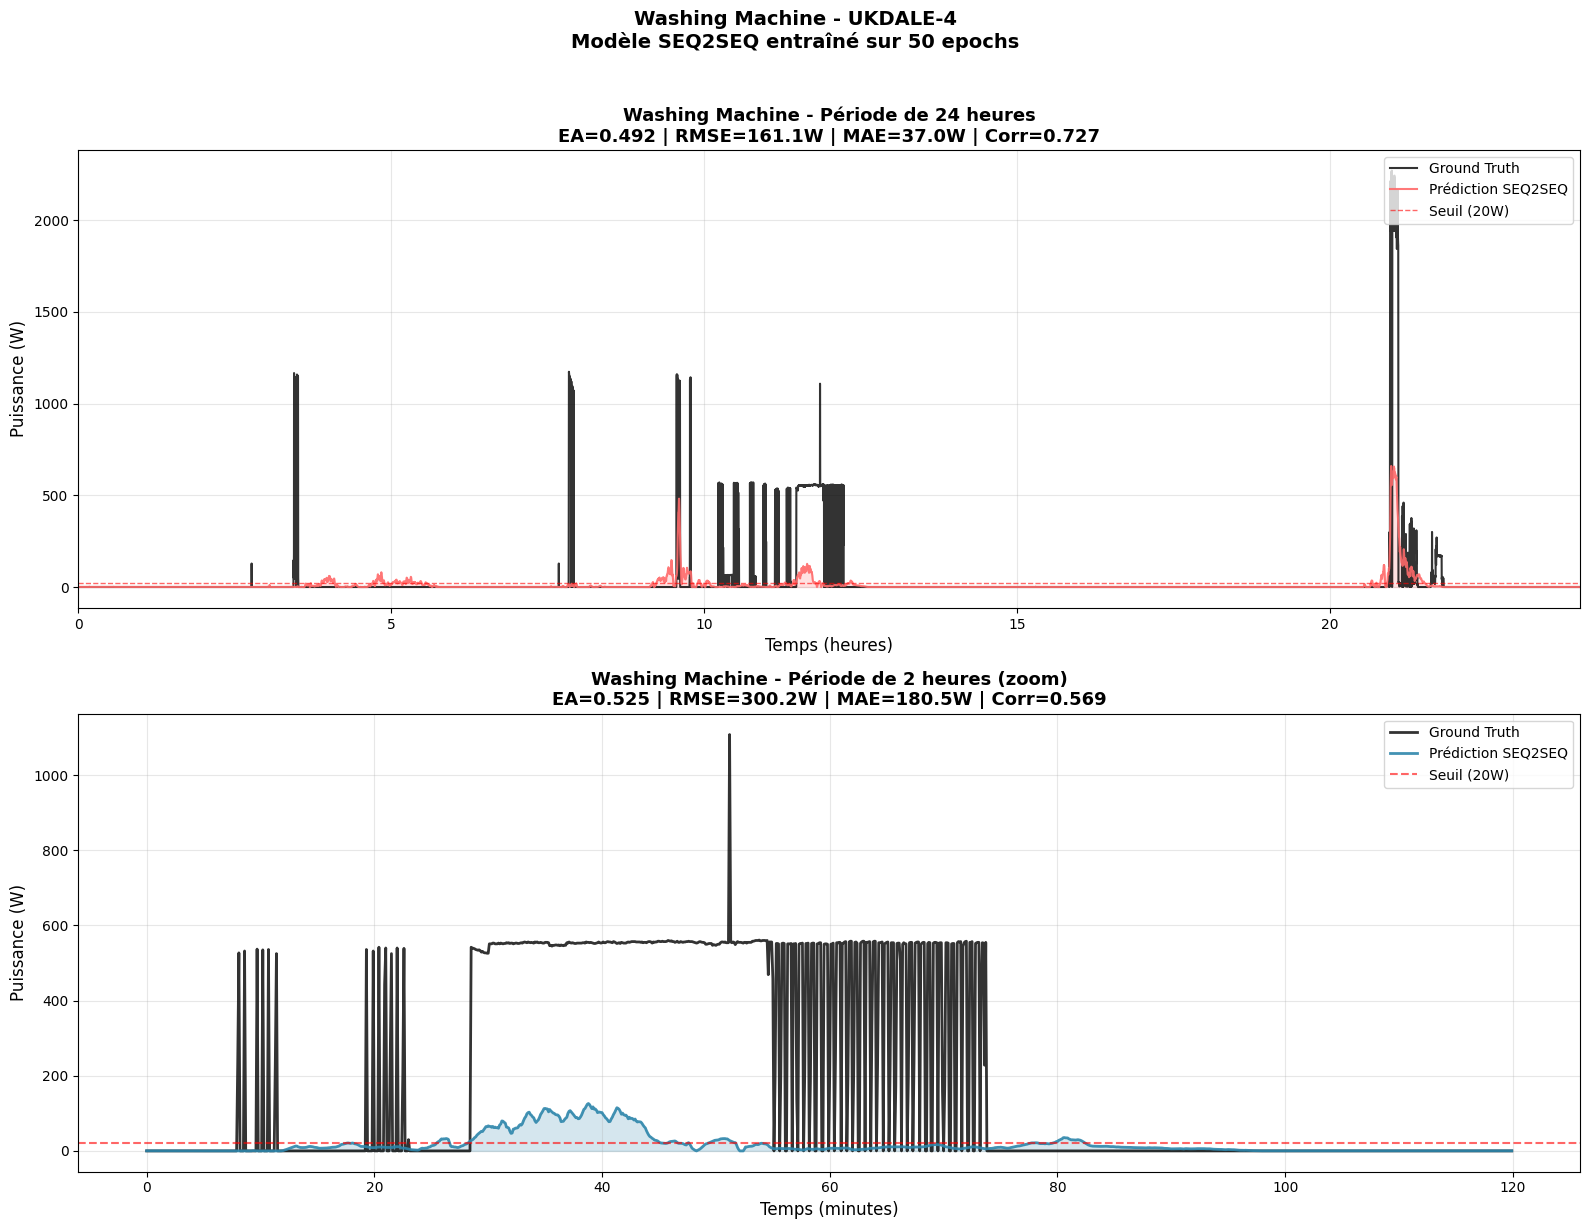

💾 Graphique sauvegardé: washing_machine_seq2seq_24h_2h_ukdale-4.png


In [21]:
# ============================================================================
# CELL: VISUALISATION PRÉDICTIONS VS GROUND TRUTH
# Périodes: 1 journée (24h) et 2 heures
# ============================================================================

def plot_predictions_periods(test_data, model_info, model_type='seq2seq', 
                             threshold=20, appliance_name="Washing Machine"):
    """
    Affiche les prédictions vs ground truth sur deux périodes:
    - Une journée complète (24h)
    - Une fenêtre de 2 heures
    """
    
    df = test_data['df']
    wm_meter = test_data['wm_meter']
    
    if wm_meter not in df.columns:
        print(f"❌ {wm_meter} non trouvé!")
        return
    
    power = df[wm_meter].values
    mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
    
    # Période 1: Une journée (24h = 14400 points car 6s d'intervalle)
    # 24h * 3600s / 6s = 14400 points
    day_points = 24 * 3600 // 6  # 14400 points
    
    # Trouver une période avec activité
    above = (power > threshold).astype(int)
    changes = np.diff(np.concatenate(([0], above, [0])))
    starts = np.where(changes == 1)[0]
    
    if len(starts) > 0:
        # Prendre un événement au milieu des données
        mid_event = starts[len(starts)//2]
        day_start = max(0, mid_event - day_points//2)
    else:
        day_start = 0
    
    if day_start + day_points > len(power):
        day_start = max(0, len(power) - day_points)
    day_end = day_start + day_points
    
    # Période 2: 2 heures
    hours_2_points = 2 * 3600 // 6  # 1200 points
    
    if len(starts) > 0:
        two_hour_start = max(0, starts[len(starts)//2] - hours_2_points//2)
    else:
        two_hour_start = day_start + day_points//2 - hours_2_points//2
    
    if two_hour_start + hours_2_points > len(power):
        two_hour_start = max(0, len(power) - hours_2_points)
    two_hour_end = two_hour_start + hours_2_points
    
    # Prédictions pour les deux périodes
    day_true = power[day_start:day_end]
    day_mains = pd.Series(mains_vals[day_start:day_end])
    day_pred = predict_washingmachine(day_mains, model_info, model_type)
    day_pred = np.clip(day_pred, 0, None)
    
    hour_true = power[two_hour_start:two_hour_end]
    hour_mains = pd.Series(mains_vals[two_hour_start:two_hour_end])
    hour_pred = predict_washingmachine(hour_mains, model_info, model_type)
    hour_pred = np.clip(hour_pred, 0, None)
    
    # Calcul des métriques
    min_len_day = min(len(day_true), len(day_pred))
    metrics_day = NILMMetrics.compute_all(day_true[:min_len_day], day_pred[:min_len_day], threshold)
    
    min_len_hour = min(len(hour_true), len(hour_pred))
    metrics_hour = NILMMetrics.compute_all(hour_true[:min_len_hour], hour_pred[:min_len_hour], threshold)
    
    # Création des graphiques
    fig = plt.figure(figsize=(16, 12))
    
    # Journée complète
    ax1 = plt.subplot(2, 1, 1)
    time_day = np.arange(len(day_true[:min_len_day])) * 6 / 3600  # en heures
    
    ax1.plot(time_day, day_true[:min_len_day], 'black', linewidth=1.5, alpha=0.8, label='Ground Truth')
    ax1.plot(time_day, day_pred[:min_len_day], '#FF6B6B', linewidth=1.5, alpha=0.9, 
             label=f'Prédiction {model_type.upper()}')
    ax1.fill_between(time_day, 0, day_pred[:min_len_day], alpha=0.2, color='#FF6B6B')
    ax1.axhline(threshold, color='red', linestyle='--', linewidth=1, alpha=0.6, label=f'Seuil ({threshold}W)')
    
    ax1.set_ylabel('Puissance (W)', fontsize=12)
    ax1.set_title(f'{appliance_name} - Période de 24 heures\n'
                  f'EA={metrics_day["ea"]:.3f} | RMSE={metrics_day["rmse"]:.1f}W | '
                  f'MAE={metrics_day["mae"]:.1f}W | Corr={metrics_day["corr"]:.3f}',
                  fontsize=13, fontweight='bold')
    ax1.legend(loc='upper right')
    ax1.grid(True, alpha=0.3)
    ax1.set_xlabel('Temps (heures)', fontsize=12)
    ax1.set_xlim([0, 24])
    
    # Fenêtre de 2 heures
    ax2 = plt.subplot(2, 1, 2)
    time_hour = np.arange(len(hour_true[:min_len_hour])) * 6 / 60  # en minutes
    
    ax2.plot(time_hour, hour_true[:min_len_hour], 'black', linewidth=2, alpha=0.8, label='Ground Truth')
    ax2.plot(time_hour, hour_pred[:min_len_hour], '#2E86AB', linewidth=2, alpha=0.9,
             label=f'Prédiction {model_type.upper()}')
    ax2.fill_between(time_hour, 0, hour_pred[:min_len_hour], alpha=0.2, color='#2E86AB')
    ax2.axhline(threshold, color='red', linestyle='--', linewidth=1.5, alpha=0.6, label=f'Seuil ({threshold}W)')
    
    ax2.set_ylabel('Puissance (W)', fontsize=12)
    ax2.set_title(f'{appliance_name} - Période de 2 heures (zoom)\n'
                  f'EA={metrics_hour["ea"]:.3f} | RMSE={metrics_hour["rmse"]:.1f}W | '
                  f'MAE={metrics_hour["mae"]:.1f}W | Corr={metrics_hour["corr"]:.3f}',
                  fontsize=13, fontweight='bold')
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3)
    ax2.set_xlabel('Temps (minutes)', fontsize=12)
    
    plt.suptitle(f'{appliance_name} - {test_data["name"]}\n'
                 f'Modèle {model_type.upper()} entraîné sur 50 epochs',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # Sauvegarde
    fname = f'{appliance_name.lower().replace(" ", "_")}_{model_type}_24h_2h_{test_data["name"].lower()}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 Graphique sauvegardé: {fname}")
    
    return {'day': metrics_day, 'hour': metrics_hour}


# ============================================================================
# EXÉCUTION POUR HOUSE_2 ET HOUSE_4
# ============================================================================

if washingmachine_models and DATA_TEST:
    print("="*70)
    print("📊 VISUALISATION PRÉDICTIONS VS GROUND TRUTH")
    print("Périodes: 24 heures (jour complet) et 2 heures (zoom)")
    print("="*70)
    
    # Pour house_2 (test sur maison 2)
    if DATA_TEST['name'] == 'UKDALE-2':
        print("\n" + "="*50)
        print("🏠 HOUSE_2 (UKDALE-2) - Maison de test")
        print("="*50)
        
        for model_type, model_info in washingmachine_models.items():
            if model_info is None:
                continue
            print(f"\n📈 Modèle {model_type.upper()}:")
            metrics_periods = plot_predictions_periods(
                DATA_TEST, model_info, model_type,
                threshold=Config.get_threshold(),
                appliance_name="Washing Machine"
            )
    
    # Pour house_4 (si chargé séparément)
    print("\n" + "="*70)
    print("🏠 HOUSE_4 (UKDALE-4) - Test cross-house")
    print("="*70)
    
    # Charger house_4 pour visualisation
    if loader:
        house4_test = loader.load_house_data('house_4', mode='test', max_samples=Config.MAX_TEST_SAMPLES)
        if house4_test:
            for model_type, model_info in washingmachine_models.items():
                if model_info is None:
                    continue
                print(f"\n📈 Modèle {model_type.upper()} sur house_4:")
                metrics_periods = plot_predictions_periods(
                    house4_test, model_info, model_type,
                    threshold=Config.get_threshold(),
                    appliance_name="Washing Machine"
                )
else:
    print("❌ Modèles ou données non disponibles")